In [103]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import umap
import hdbscan
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

In [ ]:
# ----------------------------------
# Config
# ----------------------------------
DATA_DIR = Path("data_processed")

STOCKS_FILE = DATA_DIR / "stocks_clean.parquet"
ETFS_FILE = DATA_DIR / "etfs_clean.parquet"
META_FILE = DATA_DIR / "metadata_clean.parquet"

RETURNS_MATRIX_FILE = DATA_DIR / "returns_matrix.parquet"
RETURNS_TIDY_FILE = DATA_DIR / "returns_tidy.parquet"
ETF_RETURNS_FILE = DATA_DIR / "etf_returns.parquet"

# Minimum number of daily observations for a stock to be kept
MIN_OBS = 252 * 3   # ~3 years of daily data

stocks = pd.read_parquet(STOCKS_FILE)
meta = pd.read_parquet(META_FILE)


In [27]:
stocks.head()

,Date,Open,High,Low,Close,Adj Close,Volume,Symbol,volatility,Symbol
0,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300,A,0.032967,A
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100,A,0.059680,A
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800,A,0.065053,A
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600,A,0.058824,A
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200,A,0.023364,A


In [28]:
def normalize_columns(df):
    """
    Normalizes column names across stocks, ETFs, metadata so everything
    uses consistent naming:
    - lowercase everything
    - rename to standardized names
    """
    df = df.copy()
    df.columns = [c.lower().strip() for c in df.columns]

    rename_map = {
        "symbol": "Symbol",
        "ticker": "Ticker",        
        "date": "Date",
        "adj close": "Adj Close",
        "adj_close": "Adj Close",
        "adjclose": "Adj Close",
        "close": "Close",
        "open": "Open",
        "high": "High",
        "low": "Low",
        "volume": "Volume",

        # metadata fields
        "sector": "sector",
        "industry": "industry",
        "name": "name",
        "country": "country"
    }

    # Apply renaming where columns exist
    for old, new in rename_map.items():
        if old in df.columns:
            df = df.rename(columns={old: new})

    return df

# Step 1 — Build the Log-Returns Dataset

=== Loaded cleaned data ===
Stocks:   5615 symbols, 22,140,214 rows
Metadata: 8049 symbols

After MIN_OBS filter:
  Symbols kept: 4626 (>= 756 obs)
  Rows:         21,770,557

After metadata alignment:
  Symbols kept: 4623

Price matrix shape: (14663, 4623)
Skipping NaN filtering — data assumed clean from preprocessing.



/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/pandas/core/internals/blocks.py:395: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


Returns matrix shape: (14662, 4623)
Saved: data_processed/returns_matrix.parquet 

Tidy returns shape: (21715206, 16)


,Date,Symbol,log_return,nasdaq_traded,security_name,listing_exchange,market_category,etf,round_lot_size,test_issue,financial_status,nasdaq_symbol,nextshares,market_category_label,financial_status_label,sector
0,1962-01-03,AA,0.015212,True,Alcoa Corporation Common Stock,N,None,False,100.0,False,None,AA,False,None,None,Basic Materials
1,1962-01-03,ARNC,0.015180,True,Arconic Corporation Common Stock,N,None,False,100.0,False,None,ARNC,False,None,None,None
2,1962-01-03,BA,0.019803,True,Boeing Company (The) Common Stock,N,None,False,100.0,False,None,BA,False,None,None,Industrials
3,1962-01-03,DIS,0.013333,True,Walt Disney Company (The) Common Stock,N,None,False,100.0,False,None,DIS,False,None,None,Communication Services
4,1962-01-03,GE,-0.010084,True,General Electric Company Common Stock,N,None,False,100.0,False,None,GE,False,None,None,Industrials


Saved: data_processed/returns_tidy.parquet 

Saved ETF returns → data_processed/etf_returns.parquet


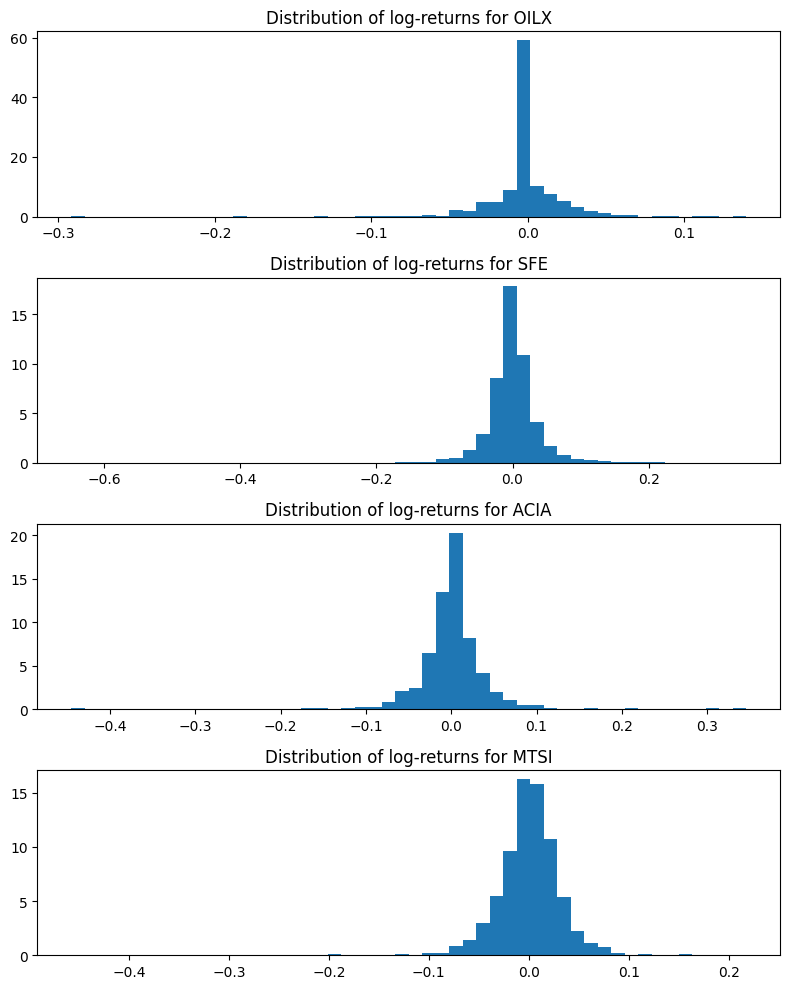

Step 1 completed.


In [32]:
# ----------------------------------
# 1. Load cleaned datasets
# ----------------------------------
stocks = normalize_columns(pd.read_parquet(STOCKS_FILE))
meta   = normalize_columns(pd.read_parquet(META_FILE))

print("=== Loaded cleaned data ===")
print(f"Stocks:   {stocks['Symbol'].nunique()} symbols, {len(stocks):,} rows")
print(f"Metadata: {meta['Symbol'].nunique()} symbols\n")

try:
    etfs = normalize_columns(pd.read_parquet(ETFS_FILE))
except:
    etfs = None


# ----------------------------------
# 2. Ensure correct structure
# ----------------------------------
stocks["Date"] = pd.to_datetime(stocks["Date"])
stocks = stocks.sort_values(["Date", "Symbol"])


# ----------------------------------
# 3. Filter universe (only MIN_OBS)
# ----------------------------------
obs = stocks.groupby("Symbol")["Date"].count()
eligible = obs[obs >= MIN_OBS].index

stocks = stocks[stocks["Symbol"].isin(eligible)]

print("After MIN_OBS filter:")
print(f"  Symbols kept: {stocks['Symbol'].nunique()} (>= {MIN_OBS} obs)")
print(f"  Rows:         {len(stocks):,}\n")


# Metadata alignment
valid_symbols = set(stocks["Symbol"].unique()) & set(meta["Symbol"].unique())

stocks = stocks[stocks["Symbol"].isin(valid_symbols)]
meta   = meta[meta["Symbol"].isin(valid_symbols)]

print("After metadata alignment:")
print(f"  Symbols kept: {len(valid_symbols)}\n")


# ----------------------------------
# 4. Build price matrix (Adj Close)
# ----------------------------------
prices = (
    stocks
    .pivot(index="Date", columns="Symbol", values="Adj Close")
    .sort_index()
)

print("Price matrix shape:", prices.shape)

# --- NO NaN filtering ---
print("Skipping NaN filtering — data assumed clean from preprocessing.\n")


# Compute log returns
returns_matrix = np.log(prices).diff().iloc[1:]

print("Returns matrix shape:", returns_matrix.shape)


# ----------------------------------
# 5. Save returns matrix
# ----------------------------------
returns_matrix.to_parquet(RETURNS_MATRIX_FILE)
print("Saved:", RETURNS_MATRIX_FILE, "\n")


# ----------------------------------
# 6. Build tidy returns
# ----------------------------------
returns_tidy = (
    returns_matrix
    .stack()
    .rename("log_return")
    .reset_index()
)

# merge metadata
returns_tidy = returns_tidy.merge(meta, on="Symbol", how="left")

print("Tidy returns shape:", returns_tidy.shape)
display(returns_tidy.head())

returns_tidy.to_parquet(RETURNS_TIDY_FILE, index=False)
print("Saved:", RETURNS_TIDY_FILE, "\n")


# ----------------------------------
# 7. ETF returns
# ----------------------------------
if etfs is not None:
    etfs["Date"] = pd.to_datetime(etfs["Date"])
    etfs = etfs.sort_values(["Date", "Symbol"])

    etf_prices = (
        etfs
        .pivot(index="Date", columns="Symbol", values="Adj Close")
        .sort_index()
    )

    etf_returns = np.log(etf_prices).diff().iloc[1:]
    etf_returns.to_parquet(ETF_RETURNS_FILE)

    print("Saved ETF returns →", ETF_RETURNS_FILE)
else:
    print("Skipping ETF returns — no ETF data found.\n")


# ----------------------------------
# 8. Quick sanity plots
# ----------------------------------
sample_symbols = np.random.choice(returns_matrix.columns, size=min(4, len(returns_matrix.columns)), replace=False)

fig, axes = plt.subplots(len(sample_symbols), 1, figsize=(8, 2.5 * len(sample_symbols)))
if len(sample_symbols) == 1:
    axes = [axes]

for ax, sym in zip(axes, sample_symbols):
    ax.hist(returns_matrix[sym].dropna(), bins=50, density=True)
    ax.set_title(f"Distribution of log-returns for {sym}")

plt.tight_layout()
plt.show()

print("Step 1 completed.")

In [36]:
import pandas as pd

DATA_DIR = "data_processed"

# Load the three datasets
stocks_clean      = pd.read_parquet(f"{DATA_DIR}/stocks_clean.parquet")
returns_matrix    = pd.read_parquet(f"{DATA_DIR}/returns_matrix.parquet")
returns_tidy      = pd.read_parquet(f"{DATA_DIR}/returns_tidy.parquet")

print("=== stocks_clean.parquet ===")
display(stocks_clean.head())

print("\n=== returns_matrix.parquet ===")
display(returns_matrix.head())

print("\n=== returns_tidy.parquet ===")
display(returns_tidy.head())


# Optional: check ETF returns too
try:
    etf_returns = pd.read_parquet(f"{DATA_DIR}/etf_returns.parquet")
    print("\n=== etf_returns.parquet ===")
    display(etf_returns.head())
except:
    print("\nNo ETF returns file found.")


=== stocks_clean.parquet ===


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol,Volatility,ticker
0,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300,A,0.032967,A
1,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100,A,0.059680,A
2,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800,A,0.065053,A
3,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600,A,0.058824,A
4,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200,A,0.023364,A



=== returns_matrix.parquet ===


Symbol,A,AA,AAL,AAMC,AAME,AAN,AAOI,AAON,AAP,AAPL,...,ZN,ZNGA,ZNH,ZSAN,ZTO,ZTR,ZTS,ZUMZ,ZYNE,ZYXI
Date,,,,,,,,,,,,,,,,,,,,,
1962-01-03,NaN,0.015212,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-04,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-05,NaN,-0.001209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-08,NaN,-0.033193,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1962-01-09,NaN,-0.008158,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== returns_tidy.parquet ===


,Date,Symbol,log_return,nasdaq_traded,security_name,listing_exchange,market_category,etf,round_lot_size,test_issue,financial_status,nasdaq_symbol,nextshares,market_category_label,financial_status_label,sector
0,1962-01-03,AA,0.015212,True,Alcoa Corporation Common Stock,N,None,False,100.0,False,None,AA,False,None,None,Basic Materials
1,1962-01-03,ARNC,0.015180,True,Arconic Corporation Common Stock,N,None,False,100.0,False,None,ARNC,False,None,None,None
2,1962-01-03,BA,0.019803,True,Boeing Company (The) Common Stock,N,None,False,100.0,False,None,BA,False,None,None,Industrials
3,1962-01-03,DIS,0.013333,True,Walt Disney Company (The) Common Stock,N,None,False,100.0,False,None,DIS,False,None,None,Communication Services
4,1962-01-03,GE,-0.010084,True,General Electric Company Common Stock,N,None,False,100.0,False,None,GE,False,None,None,Industrials



=== etf_returns.parquet ===


Symbol,AAAU,AADR,AAXJ,ABEQ,ACES,ACIO,ACSG,ACSI,ACT,ACWF,...,YYY,ZCAN,ZDEU,ZGBR,ZHOK,ZIG,ZJPN,ZMLP,ZROZ,ZSL
Date,,,,,,,,,,,,,,,,,,,,,
1993-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-02-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-02-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-02-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1993-02-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
stocks["year"] = stocks["Date"].dt.year
coverage = stocks.groupby("Symbol")["year"].agg(["min","max","nunique"])
coverage.head()


,min,max,nunique
Symbol,,,
A,1999,2020,22
AA,1962,2020,59
AAL,2005,2020,16
AAMC,2012,2020,9
AAME,1980,2020,41


In [39]:
stocks["Date"].min(), stocks["Date"].max()

(Timestamp('1962-01-02 00:00:00'), Timestamp('2020-04-01 00:00:00'))

Text(0.5, 1.0, 'Distribution of first available date per stock')

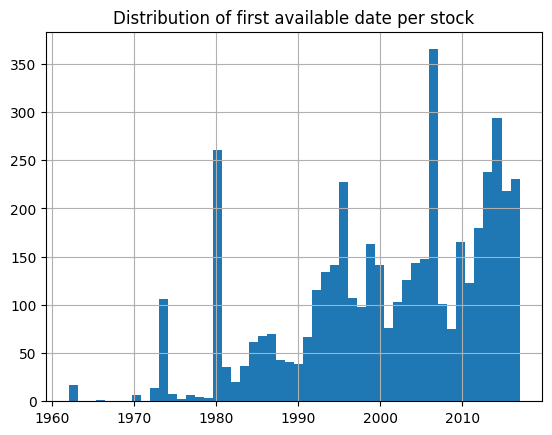

In [38]:
coverage["min"].hist(bins=50)
plt.title("Distribution of first available date per stock")


# Step 2 : 
In this step, we build the baseline correlation matrix that will serve as the foundation for all clustering and distance-based analyses.
Unlike classical pipelines, where all assets must share a common date range, here we allow each pair of stocks to use the maximum amount of information available, even if their historical data do not fully overlap.

Stocks have different start dates:
some begin in the 1980s, others IPO in 2015 or later.
If we force all assets into a common date window, we lose decades of data.
Instead, we compute correlations pairwise, using only the dates where both stocks have valid returns. This allows us to:
keep all assets
keep all historical data
capture long-term market structure
include past crises (dot-com, GFC, COVID, etc.)

Loaded returns matrix: 14662 dates × 4623 symbols


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



Correlation matrix computed.
Fraction of NaNs: 0.0017930829446144555
Distance matrix computed.
Fraction of NaNs: 0.0017930829446144555

Saved correlation matrix → data_processed/corr_baseline.parquet
Saved distance matrix → data_processed/dist_baseline.parquet


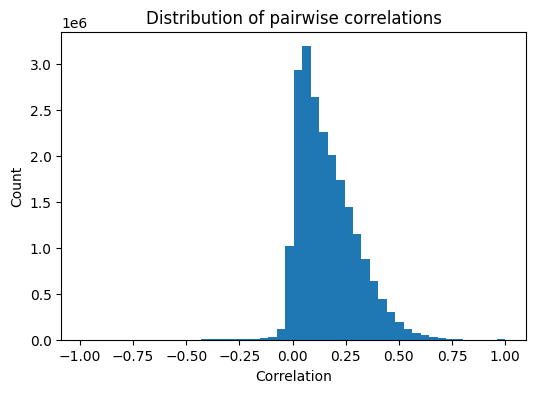

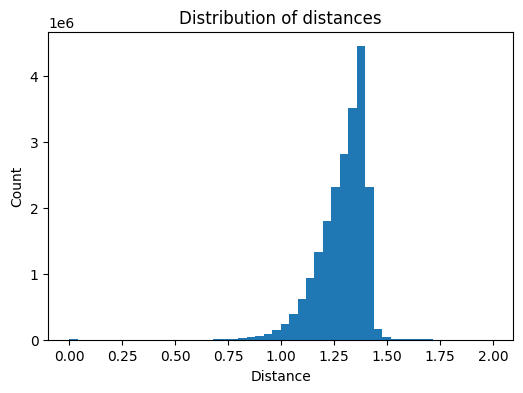

In [41]:
# 2_baseline_correlation_and_sectors.ipynb

import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# -------------------------------------
# Config
# -------------------------------------
DATA_DIR = Path("data_processed")
RETURNS_MATRIX_FILE = DATA_DIR / "returns_matrix.parquet"
META_FILE = DATA_DIR / "metadata_clean.parquet"

CORR_OUT = DATA_DIR / "corr_baseline.parquet"
DIST_OUT = DATA_DIR / "dist_baseline.parquet"

MIN_OVERLAP = 252 * 2  # at least 2 year of overlapping returns


# -------------------------------------
# Load data
# -------------------------------------
returns = pd.read_parquet(RETURNS_MATRIX_FILE)
meta = pd.read_parquet(META_FILE)

symbols = returns.columns.tolist()
print(f"Loaded returns matrix: {returns.shape[0]} dates × {len(symbols)} symbols")


# -------------------------------------
# Helper: pairwise correlation on overlapping window
# -------------------------------------
def corr_on_overlap(x, y, min_overlap=MIN_OVERLAP):
    mask = (~x.isna()) & (~y.isna())
    n = mask.sum()
    if n < min_overlap:
        return np.nan
    # correlation on overlapping returns
    return np.corrcoef(x[mask], y[mask])[0, 1]


# -------------------------------------
# Compute pairwise correlation matrix
# -------------------------------------
corr = pd.DataFrame(index=symbols, columns=symbols, dtype=float)

for i, s1 in enumerate(symbols):
    corr.loc[s1, s1] = 1.0
    for j in range(i+1, len(symbols)):
        s2 = symbols[j]
        c = corr_on_overlap(returns[s1], returns[s2])
        corr.loc[s1, s2] = c
        corr.loc[s2, s1] = c

print("\nCorrelation matrix computed.")
print("Fraction of NaNs:", corr.isna().mean().mean())


# -------------------------------------
# Convert to distance matrix
# d = sqrt(2*(1 - corr))
# -------------------------------------
dist = np.sqrt(2 * (1 - corr))

print("Distance matrix computed.")
print("Fraction of NaNs:", dist.isna().mean().mean())


# -------------------------------------
# Save outputs
# -------------------------------------
corr.to_parquet(CORR_OUT)
dist.to_parquet(DIST_OUT)

print(f"\nSaved correlation matrix → {CORR_OUT}")
print(f"Saved distance matrix → {DIST_OUT}")


# -------------------------------------
# Quick diagnostic plots
# -------------------------------------
plt.figure(figsize=(6,4))
plt.hist(corr.stack().dropna(), bins=50)
plt.title("Distribution of pairwise correlations")
plt.xlabel("Correlation")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(dist.stack().dropna(), bins=50)
plt.title("Distribution of distances")
plt.xlabel("Distance")
plt.ylabel("Count")
plt.show()


In [42]:
corr.head()

,A,AA,AAL,AAMC,AAME,AAN,AAOI,AAON,AAP,AAPL,...,ZN,ZNGA,ZNH,ZSAN,ZTO,ZTR,ZTS,ZUMZ,ZYNE,ZYXI
A,1.000000,0.385502,0.374352,0.124614,0.027707,0.189445,0.236836,0.292801,0.298319,0.351543,...,0.127091,0.227733,0.263087,0.129959,0.226061,0.254181,0.500338,0.302708,0.144931,0.041279
AA,0.385502,1.000000,0.327646,0.128501,0.031130,0.189257,0.263800,0.226327,0.299418,0.245284,...,0.125492,0.168890,0.289307,0.115984,0.189719,0.300671,0.278669,0.284015,0.180891,0.024269
AAL,0.374352,0.327646,1.000000,0.112463,0.007315,0.266829,0.207619,0.324337,0.308056,0.307292,...,0.045811,0.124513,0.286757,0.107189,0.223824,0.312105,0.330516,0.292697,0.145030,0.017359
AAMC,0.124614,0.128501,0.112463,1.000000,-0.017073,0.086519,0.085532,0.050297,0.088437,0.091706,...,0.031738,0.065287,0.097522,0.052418,0.079706,0.185006,0.157382,0.033405,0.069329,-0.014791
AAME,0.027707,0.031130,0.007315,-0.017073,1.000000,0.018813,-0.005879,0.003301,0.026305,0.036154,...,-0.006083,0.037614,0.027299,0.029340,0.018214,0.011649,0.041458,0.010676,0.043672,0.015129


In [43]:
dist.head()

,A,AA,AAL,AAMC,AAME,AAN,AAOI,AAON,AAP,AAPL,...,ZN,ZNGA,ZNH,ZSAN,ZTO,ZTR,ZTS,ZUMZ,ZYNE,ZYXI
A,0.000000,1.108601,1.118614,1.323167,1.394484,1.273228,1.235446,1.189285,1.184636,1.138821,...,1.321294,1.242793,1.214012,1.319122,1.244138,1.221327,0.999662,1.180925,1.307722,1.384718
AA,1.108601,0.000000,1.159615,1.320226,1.392027,1.273376,1.213425,1.243924,1.183708,1.228589,...,1.322504,1.289271,1.192219,1.329674,1.273013,1.182649,1.201108,1.196649,1.279929,1.396947
AAL,1.118614,1.159615,0.000000,1.332319,1.409031,1.210926,1.258873,1.162466,1.176388,1.177037,...,1.381440,1.323244,1.194356,1.336272,1.245934,1.172941,1.157137,1.189372,1.307647,1.401885
AAMC,1.323167,1.320226,1.332319,0.000000,1.426235,1.351652,1.352381,1.378190,1.350232,1.347809,...,1.391590,1.367270,1.343487,1.376649,1.356682,1.276710,1.298166,1.390392,1.364310,1.424634
AAME,1.394484,1.392027,1.409031,1.426235,0.000000,1.400847,1.418365,1.411877,1.395489,1.388414,...,1.418508,1.387362,1.394776,1.393313,1.401275,1.405952,1.384588,1.406644,1.382988,1.403475


In [44]:
corr.isna().mean().mean()

np.float64(0.0017930829446144555)

<Axes: >

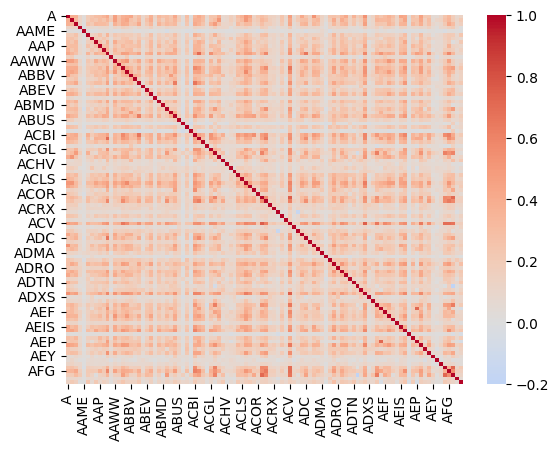

In [46]:
subset = symbols[:100]
sns.heatmap(corr.loc[subset, subset], cmap="coolwarm", center=0)


Correlation: Measuring Co-movement Between Stocks
Correlation tells us how much two stocks tend to move together:
ρ = 1.0 → perfectly aligned returns
ρ = 0 → unrelated movements
ρ < 0 → move in opposite directions
Using the overlapping-window method ensures that each pair of stocks uses all available shared history, even if their full time series do not overlap. This allows us to capture meaningful long-term relationships spanning decades.
The resulting distribution of correlations is exactly what we expect in real markets:
most pairs show weak positive correlation
few pairs exhibit strong positive correlation
almost no pairs are strongly negatively correlated
This provides confidence that the dataset and the methodology are producing realistic market structure signals.

Distance: Converting Correlation into a Clustering-Friendly Metric
While correlation is intuitive, clustering algorithms work better on a distance measure.
We convert correlation into distance using the standard transformation:

d= sqrt(2(1−ρ))
​	
 
This ensures:
highly correlated stocks → small distances
uncorrelated stocks → medium distances
negatively correlated stocks → large distances
The distance distribution we obtained is clean and well-behaved, which means:
the market structure is consistent
clustering will be stable
embeddings (e.g., UMAP) will be meaningful
This distance matrix becomes the core input for hierarchical clustering, spectral clustering, UMAP, and all other structure-revealing methods we apply later.

# Step 3 — Hierarchical Clustering (Correlation Risk Groups)

In this step, we use the distance matrix computed in Step 2 to identify
groups of stocks that share similar long-term behavior. Hierarchical
clustering is a natural choice for financial correlation structures
because it produces:

- a dendrogram (tree) showing nested similarity relationships
- cluster formations at multiple resolutions
- intuitive “risk groups” that often align with sectors or business themes

We use the **Ward linkage** method, which builds clusters by minimizing
within-cluster variance and is widely used in finance.

Because our distance matrix may contain NaNs (due to insufficient
overlap between some stocks), we work with a version where missing values
are replaced by the median distance. This allows the hierarchical
algorithm to run while preserving the main structure.

For several choices of number of clusters (e.g. k = 5, 10, 15), we:
- cut the dendrogram
- assign cluster labels to each stock
- compare these clusters to sectors using purity and contingency tables

This step produces the first set of *Correlation Risk Groups*, which will
serve as a benchmark for later clustering methods (spectral, UMAP+HDBSCAN).


In [49]:
# --------------------------------------------------
# Config
# --------------------------------------------------
DATA_DIR = Path("data_processed")
DIST_FILE = DATA_DIR / "dist_baseline.parquet"
META_FILE = DATA_DIR / "metadata_clean.parquet"

OUT_DIR = DATA_DIR / "clusters_hierarchical"
OUT_DIR.mkdir(exist_ok=True)

# Cluster counts we want to explore
K_LIST = [5, 10, 15]

Loaded distance matrix for 4623 symbols.
Distance matrix shape: (4623, 4623)
Median distance used to fill NaNs: 1.3142528413669705
Any NaNs remaining? False
Condensed distance vector length: 10683753
Linkage matrix shape: (4622, 4)


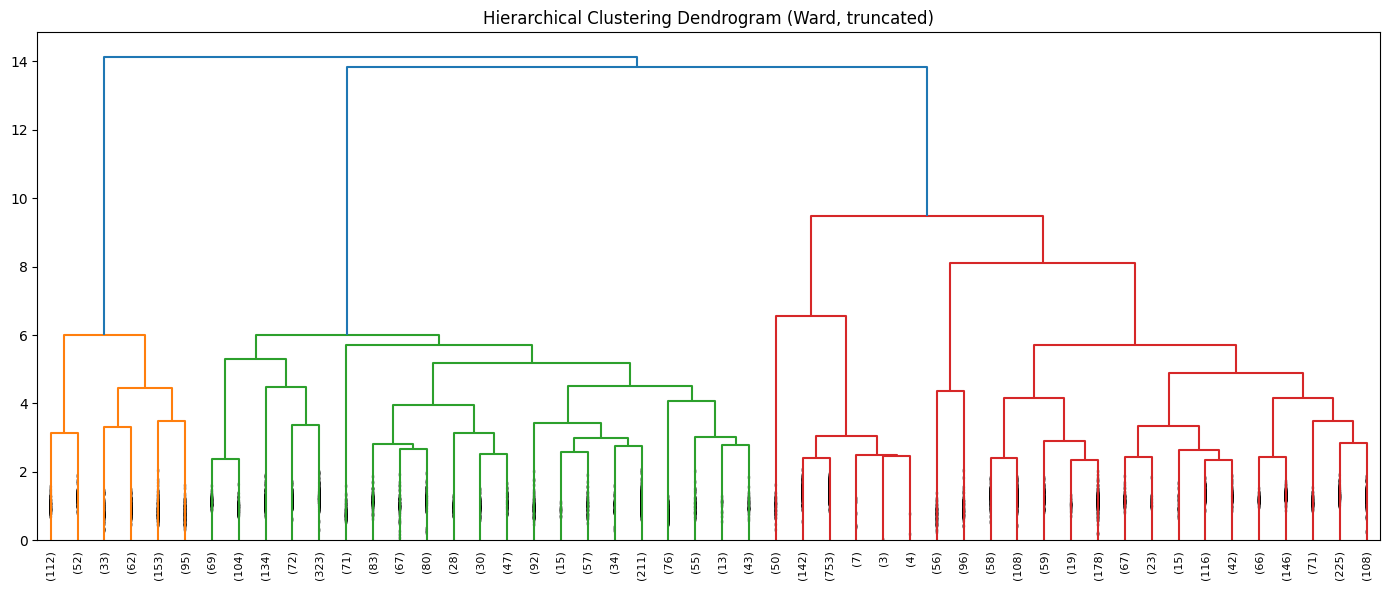

Saved truncated dendrogram to: data_processed/clusters_hierarchical/dendrogram_truncated.png

=== k = 5 ===
Saved cluster assignments to: data_processed/clusters_hierarchical/hierarchical_clusters_k5.csv
Cluster purity (w.r.t sector): 0.215

Top sector per cluster:
cluster_k5
1    Financial Services
2    Financial Services
3            Healthcare
4                Energy
5            Healthcare
Name: Sector, dtype: object

Cluster × sector table (counts):
Sector      Basic Materials  Communication Services  Consumer Cyclical  \
cluster_k5                                                               
1                         0                       0                  3   
2                        74                      51                166   
3                        45                      13                 40   
4                         2                       0                  0   
5                        28                      55                 94   

Sector      Consumer D

In [57]:
# --------------------------------------------------
# 1. Load distance matrix + metadata
# --------------------------------------------------
dist = pd.read_parquet(DIST_FILE)
meta = pd.read_parquet(META_FILE)

symbols = dist.index.tolist()
print(f"Loaded distance matrix for {len(symbols)} symbols.")
print("Distance matrix shape:", dist.shape)

# Ensure rows/cols align and labels match
assert (dist.columns.tolist() == symbols), "Distance matrix must have same row/col order"

# Keep only metadata for symbols present in dist
meta = meta[meta["symbol"].isin(symbols)].copy()


# --------------------------------------------------
# 2. Handle NaNs in the distance matrix
#    (from insufficient overlap in Step 2)
# --------------------------------------------------
# Extract upper triangle (excluding diagonal) to compute median on valid distances
upper_tri_indices = np.triu_indices(len(symbols), k=1)
upper_tri_vals = dist.values[upper_tri_indices]
median_dist = np.nanmedian(upper_tri_vals)

print("Median distance used to fill NaNs:", median_dist)

dist_filled = dist.copy()

# Fill NaNs with median distance
dist_filled = dist_filled.fillna(median_dist)

# Ensure diagonal is 0
np.fill_diagonal(dist_filled.values, 0.0)

print("Any NaNs remaining?", dist_filled.isna().any().any())


# --------------------------------------------------
# 3. Convert square distance matrix to condensed form
#    required by scipy.linkage
# --------------------------------------------------
dist_condensed = squareform(dist_filled.values)
print("Condensed distance vector length:", len(dist_condensed))


# --------------------------------------------------
# 4. Hierarchical clustering (Ward linkage)
# --------------------------------------------------
Z = linkage(dist_condensed, method="ward")
print("Linkage matrix shape:", Z.shape)


# --------------------------------------------------
# 5. Plot and save dendrogram (truncated)
# --------------------------------------------------
plt.figure(figsize=(14, 6))
plt.title("Hierarchical Clustering Dendrogram (Ward, truncated)")
# Truncate to last p merged clusters for readability
dendrogram(
    Z,
    labels=symbols,
    truncate_mode="lastp",
    p=50,                 # show only last 50 clusters
    leaf_rotation=90.,
    leaf_font_size=8.,
    show_contracted=True,
)
plt.tight_layout()
dendro_path = OUT_DIR / "dendrogram_truncated.png"
plt.savefig(dendro_path, dpi=150)
plt.show()

print("Saved truncated dendrogram to:", dendro_path)


# --------------------------------------------------
# 6. Helper: cluster purity vs sector
# --------------------------------------------------
def compute_purity(df, cluster_col, sector_col="sector"):
    """
    Purity = sum over clusters of (size of majority class in cluster) / total samples.
    """
    total = len(df)
    correct = 0
    for c in df[cluster_col].unique():
        subset = df[df[cluster_col] == c]
        if subset[sector_col].notna().sum() == 0:
            # If sector is completely missing for this cluster, skip
            continue
        counts = subset[sector_col].value_counts()
        correct += counts.iloc[0]
    return correct / total if total > 0 else np.nan


# --------------------------------------------------
# 7. Cut dendrogram at different k and evaluate
# --------------------------------------------------
cluster_results = {}

for k in K_LIST:
    labels = fcluster(Z, k, criterion="maxclust")

    df_clusters = pd.DataFrame({
        "symbol": symbols,
        f"cluster_k{k}": labels
    })

    # Merge sector/metadata info
    df_clusters = df_clusters.merge(meta, on="symbol", how="left")

    # Save cluster assignments
    out_csv = OUT_DIR / f"hierarchical_clusters_k{k}.csv"
    df_clusters.to_csv(out_csv, index=False)
    cluster_results[k] = df_clusters

    print(f"\n=== k = {k} ===")
    print("Saved cluster assignments to:", out_csv)

    # Compute purity vs sector
    purity = compute_purity(df_clusters, f"cluster_k{k}", sector_col="Sector")
    print("Cluster purity (w.r.t sector):", round(purity, 3))

    # Simple sector composition per cluster
    print("\nTop sector per cluster:")
    top_sector_per_cluster = (
        df_clusters
        .groupby(f"cluster_k{k}")["Sector"]
        .agg(lambda s: s.value_counts().index[0] if s.notna().any() else "Unknown")
    )
    print(top_sector_per_cluster)

    # Optional: sector distribution table (cluster × sector)
    print("\nCluster × sector table (counts):")
    crosstab = pd.crosstab(df_clusters[f"cluster_k{k}"], df_clusters["Sector"])
    print(crosstab.head())  # show first few clusters


# Step 4 — UMAP Embedding + HDBSCAN Density Clustering

Goal: build an intuitive 2D map of the market and detect clusters in an
unsupervised way.

We start from the pairwise distance matrix computed in Step 2. Using UMAP
with `metric="precomputed"`, we obtain a 2D embedding where:

- nearby points correspond to stocks with similar return behavior,
- distant points correspond to less related stocks.

On top of this 2D embedding, we apply HDBSCAN, a density-based clustering
algorithm that:

- automatically finds dense clusters,
- labels sparse regions and isolated points as noise (`label = -1`),
- does not require us to choose the number of clusters in advance.

We visualize the embedding:

- colored by sector (to see how economic groups arrange in the map),
- colored by HDBSCAN clusters (to see purely data-driven groups),
- with outliers highlighted.

Outputs:

- `umap_coords.csv` — 2D coordinates for each symbol
- `hdbscan_clusters.csv` — HDBSCAN labels and cluster probabilities
- high-resolution figures for later use in the blog


In [89]:
# --------------------------------------------------
# Config
# --------------------------------------------------
DATA_DIR    = Path("data_processed")
DIST_FILE   = DATA_DIR / "dist_baseline.parquet"
META_FILE   = DATA_DIR / "metadata_clean.parquet"

OUT_DIR = DATA_DIR / "embedding_umap_hdbscan"
OUT_DIR.mkdir(exist_ok=True)

UMAP_COORDS_FILE   = OUT_DIR / "umap_coords.csv"
HDBSCAN_CLUST_FILE = OUT_DIR / "hdbscan_clusters.csv"

K_VALUES = [5, 8, 10, 15]   # K-means values to explore


Original distance matrix shape: (4623, 4623)
Symbols with sector info: 3702
Final universe size after intersection: 3045
Filtered distance matrix shape: (3045, 3045)
Max distance:    1.8781
Median distance: 1.2944

Running UMAP embedding...


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding shape: (3045, 2)
Saved UMAP coordinates → data_processed/embedding_umap_hdbscan/umap_coords.csv

Using HDBSCAN min_cluster_size: 20
Running HDBSCAN clustering...
Saved HDBSCAN cluster labels → data_processed/embedding_umap_hdbscan/hdbscan_clusters.csv


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


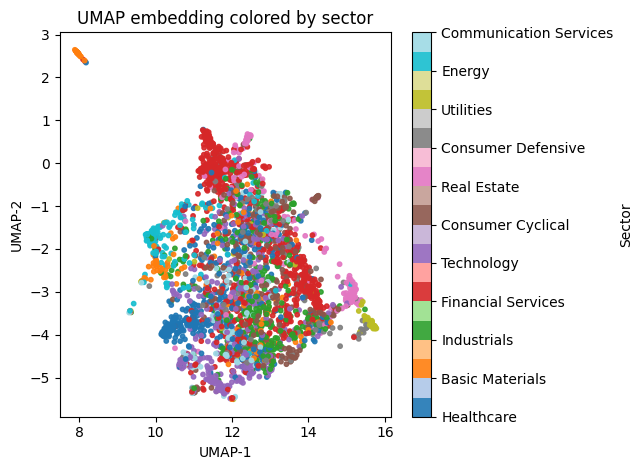

/var/folders/20/rg0jtvpx2t3_z4md2fc12g6h0000gn/T/ipykernel_73115/2946002883.py:136: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = plt.cm.get_cmap(


Saved figure → data_processed/embedding_umap_hdbscan/umap_by_sector.png
Unique HDBSCAN labels: [0 1]


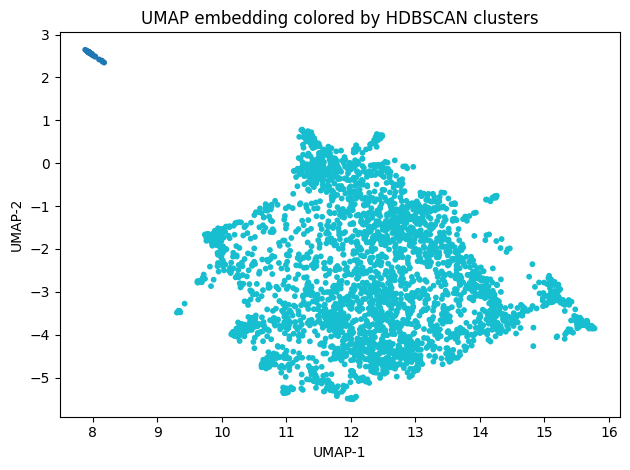

Saved figure → data_processed/embedding_umap_hdbscan/umap_by_hdbscan_clusters.png


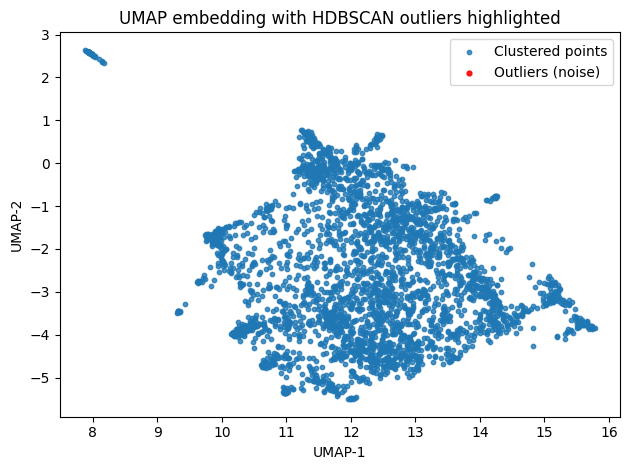

Saved figure → data_processed/embedding_umap_hdbscan/umap_with_outliers.png

=== Running K-means with k = 5 ===
Saved: data_processed/embedding_umap_hdbscan/kmeans_clusters_k5.csv


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_po

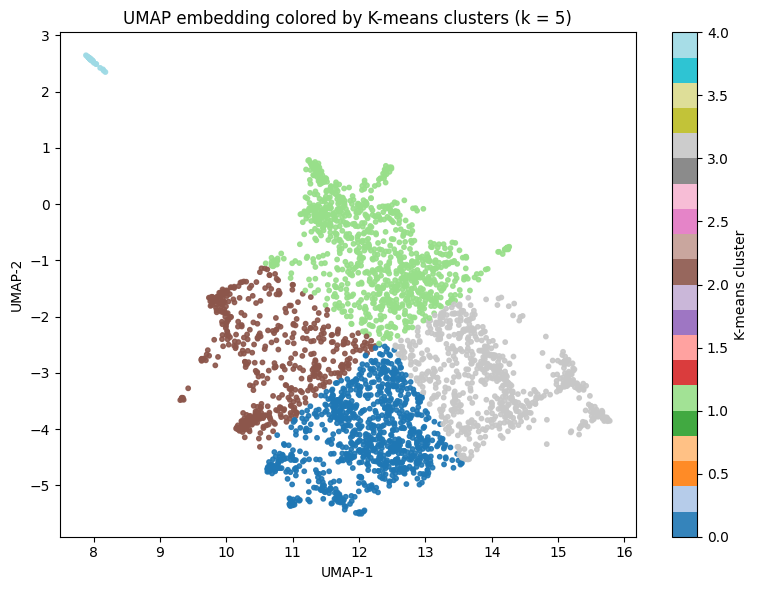

Saved figure: data_processed/embedding_umap_hdbscan/umap_kmeans_k5.png

=== Running K-means with k = 8 ===
Saved: data_processed/embedding_umap_hdbscan/kmeans_clusters_k8.csv


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_po

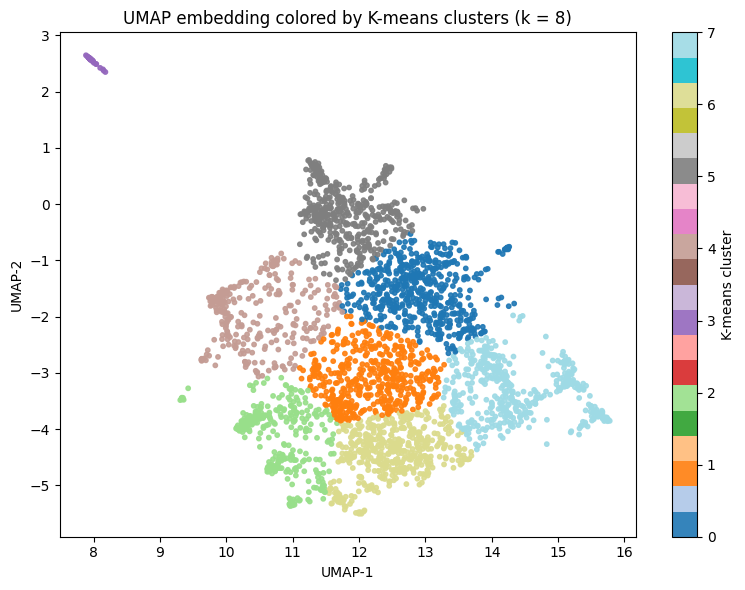

Saved figure: data_processed/embedding_umap_hdbscan/umap_kmeans_k8.png

=== Running K-means with k = 10 ===
Saved: data_processed/embedding_umap_hdbscan/kmeans_clusters_k10.csv


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_po

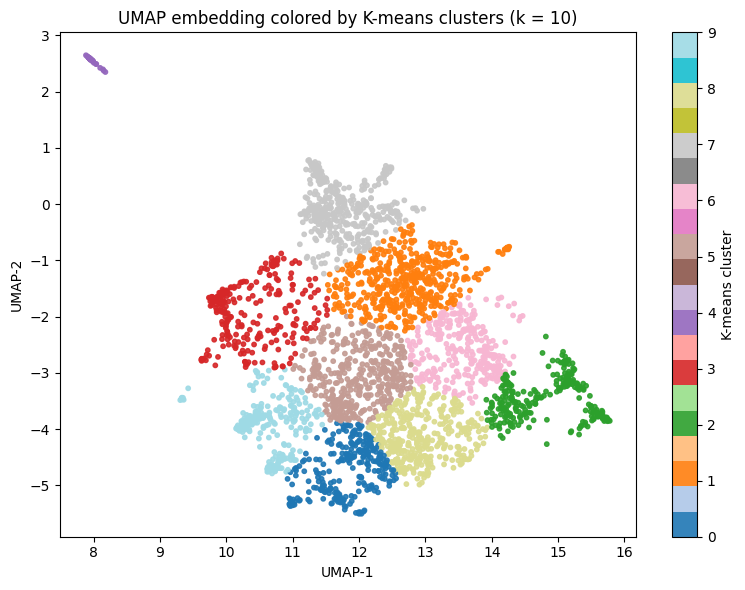

Saved figure: data_processed/embedding_umap_hdbscan/umap_kmeans_k10.png

=== Running K-means with k = 15 ===
Saved: data_processed/embedding_umap_hdbscan/kmeans_clusters_k15.csv


/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/hugo/miniconda3/envs/py/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_po

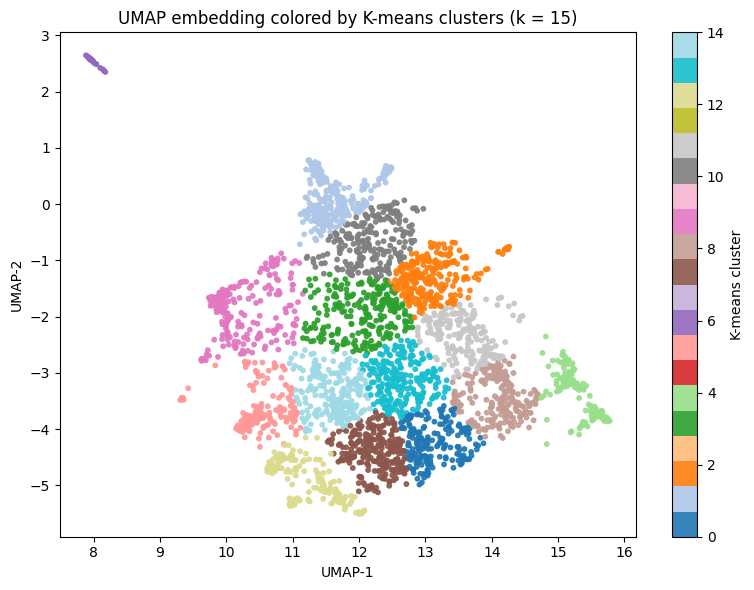

Saved figure: data_processed/embedding_umap_hdbscan/umap_kmeans_k15.png

Step 5 completed (UMAP + HDBSCAN + K-means).


In [91]:
# --------------------------------------------------
# 1. Load distance matrix + metadata
# --------------------------------------------------
dist = pd.read_parquet(DIST_FILE)
print("Original distance matrix shape:", dist.shape)

meta = pd.read_parquet(META_FILE)

# Keep only rows with a valid sector
meta_valid = meta.dropna(subset=["Sector"]).copy()
print("Symbols with sector info:", len(meta_valid))

symbols_dist = dist.index.tolist()
symbols_meta = meta_valid["symbol"].tolist()

# Intersection in distance order
valid_symbols = [s for s in symbols_dist if s in symbols_meta]
print("Final universe size after intersection:", len(valid_symbols))

dist_valid = dist.loc[valid_symbols, valid_symbols]
print("Filtered distance matrix shape:", dist_valid.shape)

meta_valid = (
    meta_valid
    .set_index("symbol")
    .loc[valid_symbols]
    .reset_index()
)


# --------------------------------------------------
# 2. Prepare distance matrix for UMAP (fill NaNs)
# --------------------------------------------------
i_upper, j_upper = np.triu_indices(len(valid_symbols), k=1)
upper_vals  = dist_valid.values[i_upper, j_upper]
valid_upper = upper_vals[~np.isnan(upper_vals)]

d_max    = np.max(valid_upper)
d_median = np.median(valid_upper)
print(f"Max distance:    {d_max:.4f}")
print(f"Median distance: {d_median:.4f}")

dist_filled = dist_valid.copy().fillna(d_max)
np.fill_diagonal(dist_filled.values, 0.0)
D = dist_filled.values


# --------------------------------------------------
# 3. UMAP embedding (metric='precomputed')
# --------------------------------------------------
reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.05,
    n_components=2,
    metric="precomputed",
    random_state=42,
)

print("\nRunning UMAP embedding...")
embedding = reducer.fit_transform(D)   # shape (n_symbols, 2)
print("Embedding shape:", embedding.shape)

umap_x = embedding[:, 0]
umap_y = embedding[:, 1]

# Save coordinates + metadata
df_umap = pd.DataFrame({
    "symbol": valid_symbols,
    "umap_x": umap_x,
    "umap_y": umap_y,
}).merge(meta_valid, on="symbol", how="left")

df_umap.to_csv(UMAP_COORDS_FILE, index=False)
print("Saved UMAP coordinates →", UMAP_COORDS_FILE)


# --------------------------------------------------
# 4. HDBSCAN clustering on UMAP embedding
# --------------------------------------------------
min_cluster_size = max(20, len(valid_symbols) // 200)  # e.g. ~20–50
print("\nUsing HDBSCAN min_cluster_size:", min_cluster_size)

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size,
    min_samples=None,
    metric="euclidean",
    cluster_selection_method="eom",
)

print("Running HDBSCAN clustering...")
hdb_labels = clusterer.fit_predict(embedding)   # -1 = noise
hdb_probs  = clusterer.probabilities_

df_hdb = pd.DataFrame({
    "symbol": valid_symbols,
    "hdbscan_label": hdb_labels,
    "hdbscan_probability": hdb_probs,
})
df_hdb.to_csv(HDBSCAN_CLUST_FILE, index=False)
print("Saved HDBSCAN cluster labels →", HDBSCAN_CLUST_FILE)

# Merge for plotting
df_all = df_umap.merge(df_hdb, on="symbol", how="left")


# --------------------------------------------------
# 5. Plots for UMAP + HDBSCAN
# --------------------------------------------------
# 5.1 UMAP colored by sector
sector_codes, sector_labels = pd.factorize(df_all["Sector"])

plt.figure()
scatter = plt.scatter(
    df_all["umap_x"], df_all["umap_y"],
    c=sector_codes, cmap="tab20", s=10, alpha=0.9
)
plt.title("UMAP embedding colored by sector")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
cbar = plt.colorbar(scatter)
cbar.set_ticks(range(len(sector_labels)))
cbar.set_ticklabels(sector_labels)
cbar.set_label("Sector")

plt.tight_layout()
fig_sector = OUT_DIR / "umap_by_sector.png"
plt.savefig(fig_sector, dpi=200)
plt.show()
print("Saved figure →", fig_sector)

# 5.2 UMAP colored by HDBSCAN clusters
unique_labels = np.unique(hdb_labels)
print("Unique HDBSCAN labels:", unique_labels)

if np.any(unique_labels >= 0):
    palette = plt.cm.get_cmap(
        "tab10", int(unique_labels[unique_labels >= 0].max()) + 1
    )
else:
    palette = plt.cm.get_cmap("tab10", 1)

colors = []
for lbl in hdb_labels:
    if lbl == -1:
        colors.append((0.7, 0.7, 0.7, 0.5))  # noise = gray
    else:
        colors.append(palette(int(lbl)))

plt.figure()
plt.scatter(df_all["umap_x"], df_all["umap_y"], c=colors, s=10)
plt.title("UMAP embedding colored by HDBSCAN clusters")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.tight_layout()
fig_hdb = OUT_DIR / "umap_by_hdbscan_clusters.png"
plt.savefig(fig_hdb, dpi=200)
plt.show()
print("Saved figure →", fig_hdb)

# 5.3 UMAP with outliers highlighted
is_noise   = df_all["hdbscan_label"] == -1
is_cluster = ~is_noise

plt.figure()
plt.scatter(
    df_all.loc[is_cluster, "umap_x"],
    df_all.loc[is_cluster, "umap_y"],
    c="tab:blue", s=10, alpha=0.8, label="Clustered points"
)
plt.scatter(
    df_all.loc[is_noise, "umap_x"],
    df_all.loc[is_noise, "umap_y"],
    c="red", s=12, alpha=0.9, label="Outliers (noise)"
)
plt.title("UMAP embedding with HDBSCAN outliers highlighted")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend()
plt.tight_layout()
fig_outliers = OUT_DIR / "umap_with_outliers.png"
plt.savefig(fig_outliers, dpi=200)
plt.show()
print("Saved figure →", fig_outliers)


# --------------------------------------------------
# 6. K-MEANS CLUSTERING ON UMAP COORDINATES
# --------------------------------------------------
umap_coords = embedding  # (n_samples, 2)

for k in K_VALUES:
    print(f"\n=== Running K-means with k = {k} ===")
    
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    km_labels = kmeans.fit_predict(umap_coords)
    
    df_km = df_all.copy()
    df_km["kmeans_cluster"] = km_labels
    
    # Save cluster assignments
    km_csv = OUT_DIR / f"kmeans_clusters_k{k}.csv"
    df_km.to_csv(km_csv, index=False)
    print("Saved:", km_csv)
    
    # Plot clusters on UMAP
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df_km["umap_x"], df_km["umap_y"],
        c=km_labels, cmap="tab20", s=10, alpha=0.9
    )
    plt.colorbar(scatter, label="K-means cluster")
    plt.title(f"UMAP embedding colored by K-means clusters (k = {k})")
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.tight_layout()
    
    km_fig = OUT_DIR / f"umap_kmeans_k{k}.png"
    plt.savefig(km_fig, dpi=200)
    plt.show()
    print("Saved figure:", km_fig)

print("\nStep 5 completed (UMAP + HDBSCAN + K-means).")

In [78]:
df_umap = pd.read_csv(UMAP_COORDS_FILE)
df_clust = pd.read_csv(HDBSCAN_CLUST_FILE)

df = df_umap.merge(df_clust, on="symbol", how="left")

# Inspect the extrema of the embedding
print(df[['umap_x', 'umap_y']].describe())

            umap_x       umap_y
count  3045.000000  3045.000000
mean     12.290460    -2.579829
std       1.363656     1.601278
min       7.883350    -5.505783
25%      11.447604    -3.812467
50%      12.299184    -2.873650
75%      13.086678    -1.461264
max      15.778506     2.645361


In [80]:
isolated = df[df["umap_x"] < 9]
print(len(isolated))
isolated

39


,symbol,umap_x,umap_y,nasdaq_traded,security_name,listing_exchange,market_category,etf,round_lot_size,test_issue,financial_status,nasdaq_symbol,nextshares,market_category_label,financial_status_label,Sector,hdbscan_label,hdbscan_probability
64,AG,7.970552,2.555396,True,First Majestic Silver Corp. Ordinary Shares (C...,N,NaN,False,100.0,False,NaN,AG,False,NaN,NaN,Basic Materials,0,0.864305
68,AGI,7.939292,2.589129,True,Alamos Gold Inc. Class A Common Shares,N,NaN,False,100.0,False,NaN,AGI,False,NaN,NaN,Basic Materials,0,1.000000
198,ASA,7.963154,2.564544,True,ASA Gold and Precious Metals Limited,N,NaN,False,100.0,False,NaN,ASA,False,NaN,NaN,Financial Services,0,1.000000
205,ASM,7.986390,2.542284,True,Avino Silver & Gold Mines Ltd. Common Shares (...,A,NaN,False,100.0,False,NaN,ASM,False,NaN,NaN,Basic Materials,0,0.626869
238,AU,7.937979,2.590896,True,AngloGold Ashanti Limited Common Stock,N,NaN,False,100.0,False,NaN,AU,False,NaN,NaN,Basic Materials,0,1.000000
242,AUMN,7.940460,2.587847,True,Golden Minerals Company Common Stock,A,NaN,False,100.0,False,NaN,AUMN,False,NaN,NaN,Basic Materials,0,1.000000
416,BTG,7.953651,2.574368,True,B2Gold Corp Common shares (Canada),A,NaN,False,100.0,False,NaN,BTG,False,NaN,NaN,Basic Materials,0,1.000000
425,BVN,7.972457,2.559108,True,Buenaventura Mining Company Inc.,N,NaN,False,100.0,False,NaN,BVN,False,NaN,NaN,Basic Materials,0,0.887953
494,CDE,7.948417,2.566460,True,"Coeur Mining, Inc. Common Stock",N,NaN,False,100.0,False,NaN,CDE,False,NaN,NaN,Basic Materials,0,1.000000
817,DRD,7.934449,2.594254,True,DRDGOLD Limited American Depositary Shares,N,NaN,False,100.0,False,NaN,DRD,False,NaN,NaN,Basic Materials,0,1.000000


# Step 6 — Market Regimes & Time-Varying Clustering

**Goal.** Understand how the stock correlation structure and clustering
change across different market regimes (bull / bear / neutral).

We use a broad market ETF (e.g. SPY) as a proxy for the overall market
state. From its log-returns we compute:

- rolling volatility (risk),
- cumulative performance and drawdown (loss from peak),
- rolling mean return (drift).

Using simple, transparent rules on these indicators, we label each day
as one of three regimes:

- **Bear**: high volatility and deep drawdown  
- **Bull**: low volatility and positive drift  
- **Neutral**: everything else

For each regime:

1. We restrict the stocks' log-returns to days in that regime only.
2. We recompute the **pairwise correlation matrix** (same logic as in
   the baseline).
3. We convert correlations to distances.
4. We run **hierarchical clustering (Ward linkage)** and save the
   cluster assignments.

This gives a time-varying view of “correlation risk groups” and lets us
compare, for example:

- Are sectors more tightly grouped in bear markets?
- Do different sectors merge or split across regimes?
- Are some stocks’ risk groups stable across all regimes?

Outputs:

- `regimes/market_regimes.csv` — daily regime label for the market ETF  
- `regimes/corr_regime_<name>.parquet` — regime-restricted correlations  
- `regimes/dist_regime_<name>.parquet` — regime-restricted distances  
- `regimes/hierarchical/<regime>_clusters_k*.csv` — clusters per regime  
- Figures: regime timeline + dendrograms (optional, blog-ready)


In [100]:
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

DATA_DIR = Path("data_processed")

RETURNS_FILE     = DATA_DIR / "returns_matrix.parquet"
ETF_RETURNS_FILE = DATA_DIR / "etf_returns.parquet"
META_FILE        = DATA_DIR / "metadata_clean.parquet"

REGIME_DIR = DATA_DIR / "regimes"
REGIME_DIR.mkdir(exist_ok=True)

HIER_DIR = REGIME_DIR / "hierarchical"
HIER_DIR.mkdir(exist_ok=True)

ROLL_WINDOW = 60          # days for rolling vol / mean

# min overlap per regime (in days) when computing correlations
MIN_OVERLAP_PER_REGIME = {
    "bull": 252,
    "neutral": 252,
    "bear": 60,          # shorter so we can still estimate corr in crises
}

# k values for hierarchical clustering
K_LIST = [5, 10]

ETF returns shape: (6842, 2151)
Available ETF symbols: ['AAAU', 'AADR', 'AAXJ', 'ABEQ', 'ACES', 'ACIO', 'ACSG', 'ACSI', 'ACT', 'ACWF', 'ACWI', 'ACWV', 'ACWX', 'ADME', 'ADRE', 'AESR', 'AFIF', 'AFK', 'AFLG', 'AFMC', 'AFSM', 'AFTY', 'AGG', 'AGGP', 'AGGY', 'AGND', 'AGQ', 'AGT', 'AGZ', 'AGZD', 'AIA', 'AIEQ', 'AIIQ', 'AIQ', 'AIRR', 'ALFA', 'ALTS', 'ALTY', 'AMCA', 'AMLP', 'AMOM', 'AMZA', 'ANGL', 'AOA', 'AOK', 'AOM', 'AOR', 'ARCM', 'ARGT', 'ARKF', 'ARKG', 'ARKK', 'ARKQ', 'ARKW', 'ARMR', 'ASEA', 'ASET', 'ASHR', 'ASHS', 'ASHX', 'AUSF', 'AVDE', 'AVDV', 'AVEM', 'AVUS', 'AVUV', 'AWAY', 'AWTM', 'AXJL', 'BAB', 'BAPR', 'BATT', 'BAUG', 'BBAX', 'BBC', 'BBCA', 'BBEU', 'BBH', 'BBIN', 'BBJP', 'BBP', 'BBRE', 'BBSA', 'BBUS', 'BCD', 'BCI', 'BDCY', 'BDEC', 'BDRY', 'BFEB', 'BFIT', 'BFOR', 'BGRN', 'BIB', 'BIBL', 'BICK', 'BIL', 'BIS', 'BIV', 'BIZD', 'BJAN', 'BJK', 'BJUL', 'BJUN', 'BKF', 'BKLN', 'BLCN', 'BLES', 'BLHY', 'BLOK', 'BLV', 'BMAR', 'BND', 'BNDC', 'BNDW', 'BNDX', 'BNO', 'BNOV', 'BOCT', 'BOIL', 'BOND', 'BO

,count,mean,std,min,25%,50%,75%,max
return,6842.0,0.000327,0.011855,-0.115887,-0.004295,0.000658,0.005756,0.135577
index,6842.0,4.340654,2.658916,0.987908,2.702759,3.560963,5.441631,12.789779
drawdown,6842.0,-0.098998,0.120162,-0.551894,-0.162737,-0.041895,-0.008601,0.000000
rolling_vol,6783.0,0.160568,0.088706,0.049786,0.104181,0.134906,0.194712,0.755843
rolling_mean,6783.0,0.089687,0.309504,-2.216332,-0.037272,0.133663,0.274209,1.374998



Vol low  (25% quantile): 0.104
Vol high (75% quantile): 0.195
Deep drawdown threshold: -0.281

Regime counts:
regime
neutral    4718
bull       1616
bear        508
Name: count, dtype: int64
Saved regime time series → data_processed/regimes/market_regimes.csv


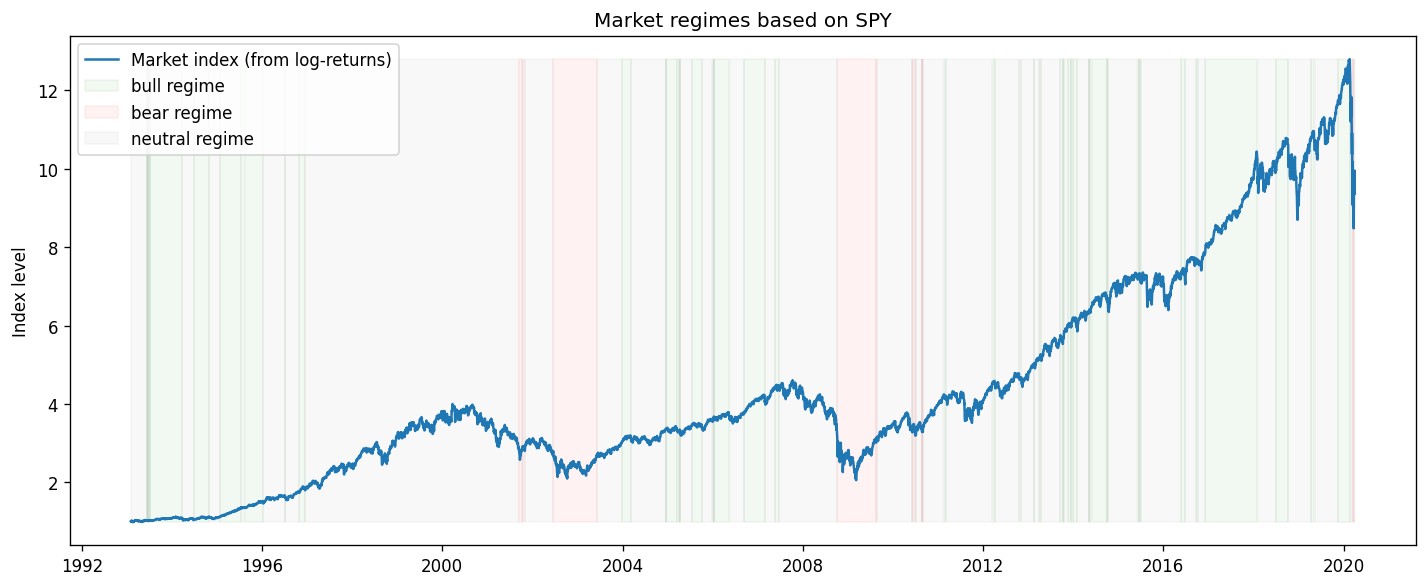

Saved regime timeline → data_processed/regimes/market_regime_timeline.png

Stock returns shape: (14662, 4623)
Metadata symbols: 8049
After metadata alignment:
  Symbols: 4623

Regime 'bull':
  Days in regime:      1616
  Rows in sub-returns: 1616
  Saved correlation → data_processed/regimes/corr_regime_bull.parquet
  Saved distance     → data_processed/regimes/dist_regime_bull.parquet
  Fraction of finite correlations in 'bull': 0.994

Regime 'neutral':
  Days in regime:      4718
  Rows in sub-returns: 4718
  Saved correlation → data_processed/regimes/corr_regime_neutral.parquet
  Saved distance     → data_processed/regimes/dist_regime_neutral.parquet
  Fraction of finite correlations in 'neutral': 0.999

Regime 'bear':
  Days in regime:      508
  Rows in sub-returns: 508
  Saved correlation → data_processed/regimes/corr_regime_bear.parquet
  Saved distance     → data_processed/regimes/dist_regime_bear.parquet
  Fraction of finite correlations in 'bear': 0.449

Global max linkage hei

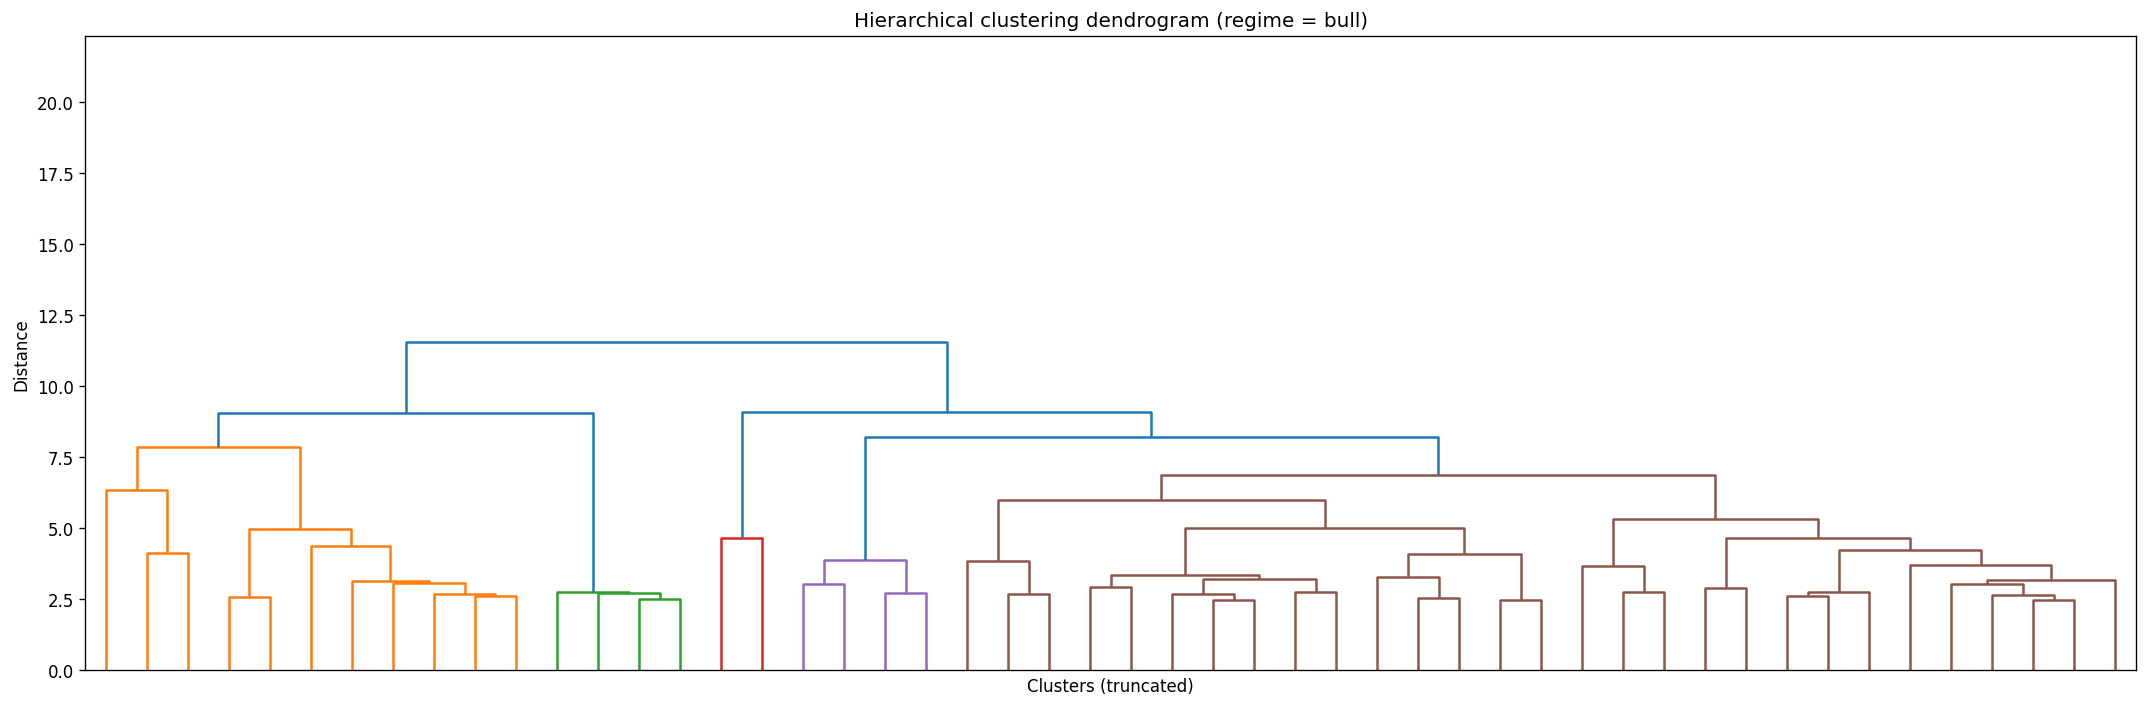

  Saved dendrogram → data_processed/regimes/hierarchical/dendrogram_bull.png
  Saved clusters (k=5) → data_processed/regimes/hierarchical/bull_clusters_k5.csv
  Saved clusters (k=10) → data_processed/regimes/hierarchical/bull_clusters_k10.csv

=== Dendrogram & clusters for regime: neutral ===


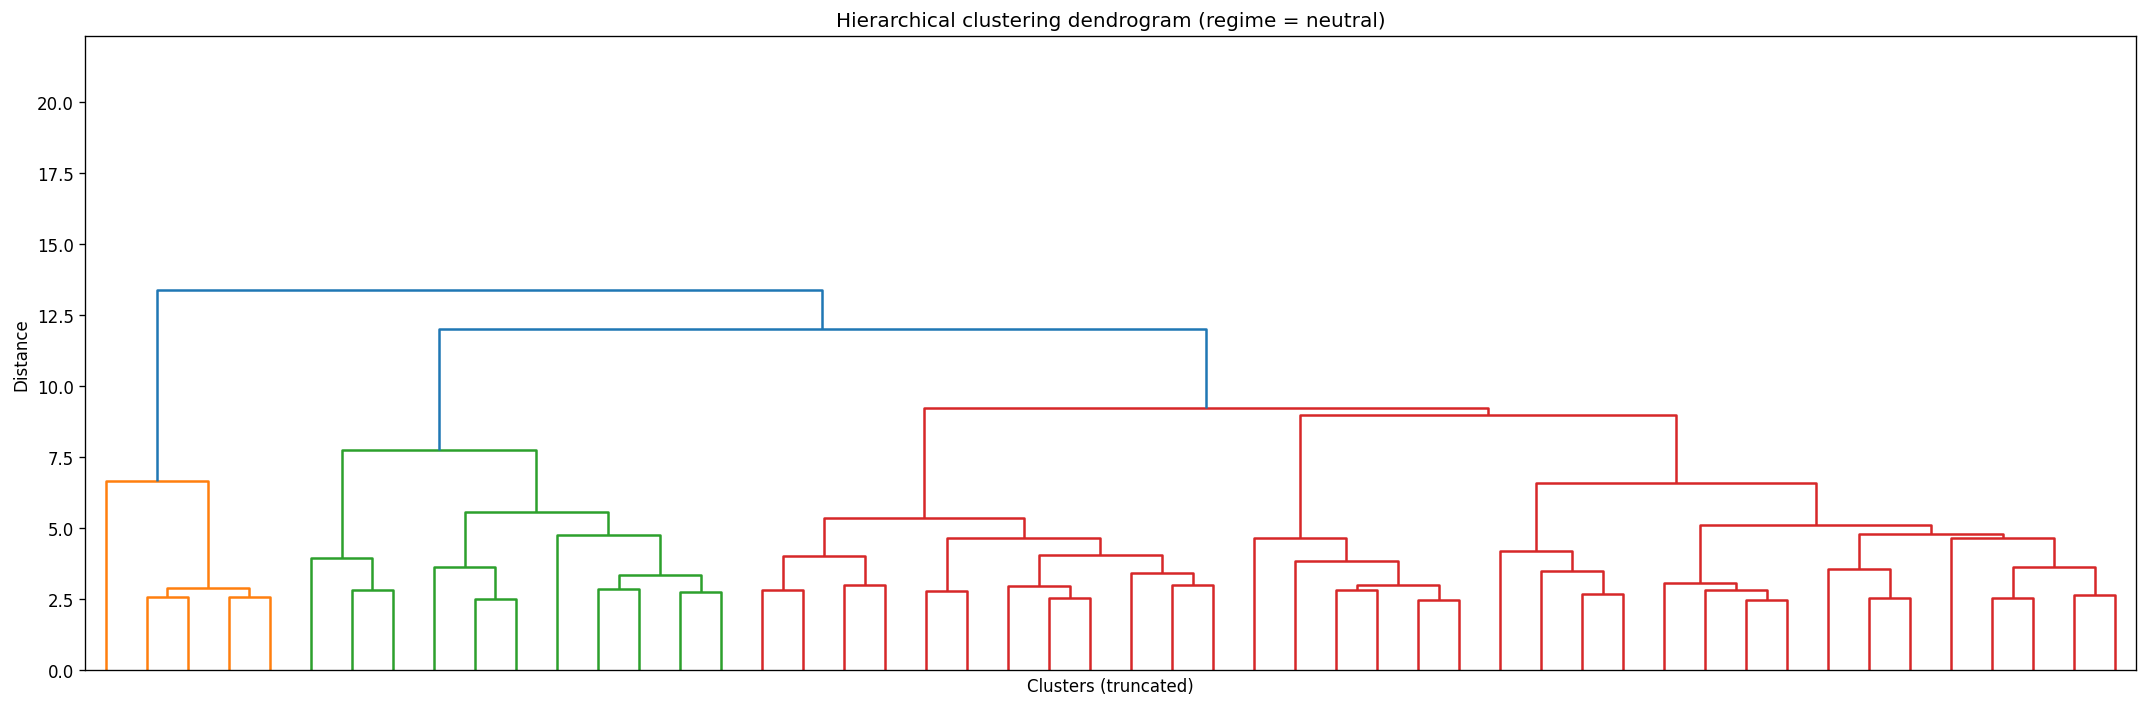

  Saved dendrogram → data_processed/regimes/hierarchical/dendrogram_neutral.png
  Saved clusters (k=5) → data_processed/regimes/hierarchical/neutral_clusters_k5.csv
  Saved clusters (k=10) → data_processed/regimes/hierarchical/neutral_clusters_k10.csv

=== Dendrogram & clusters for regime: bear ===


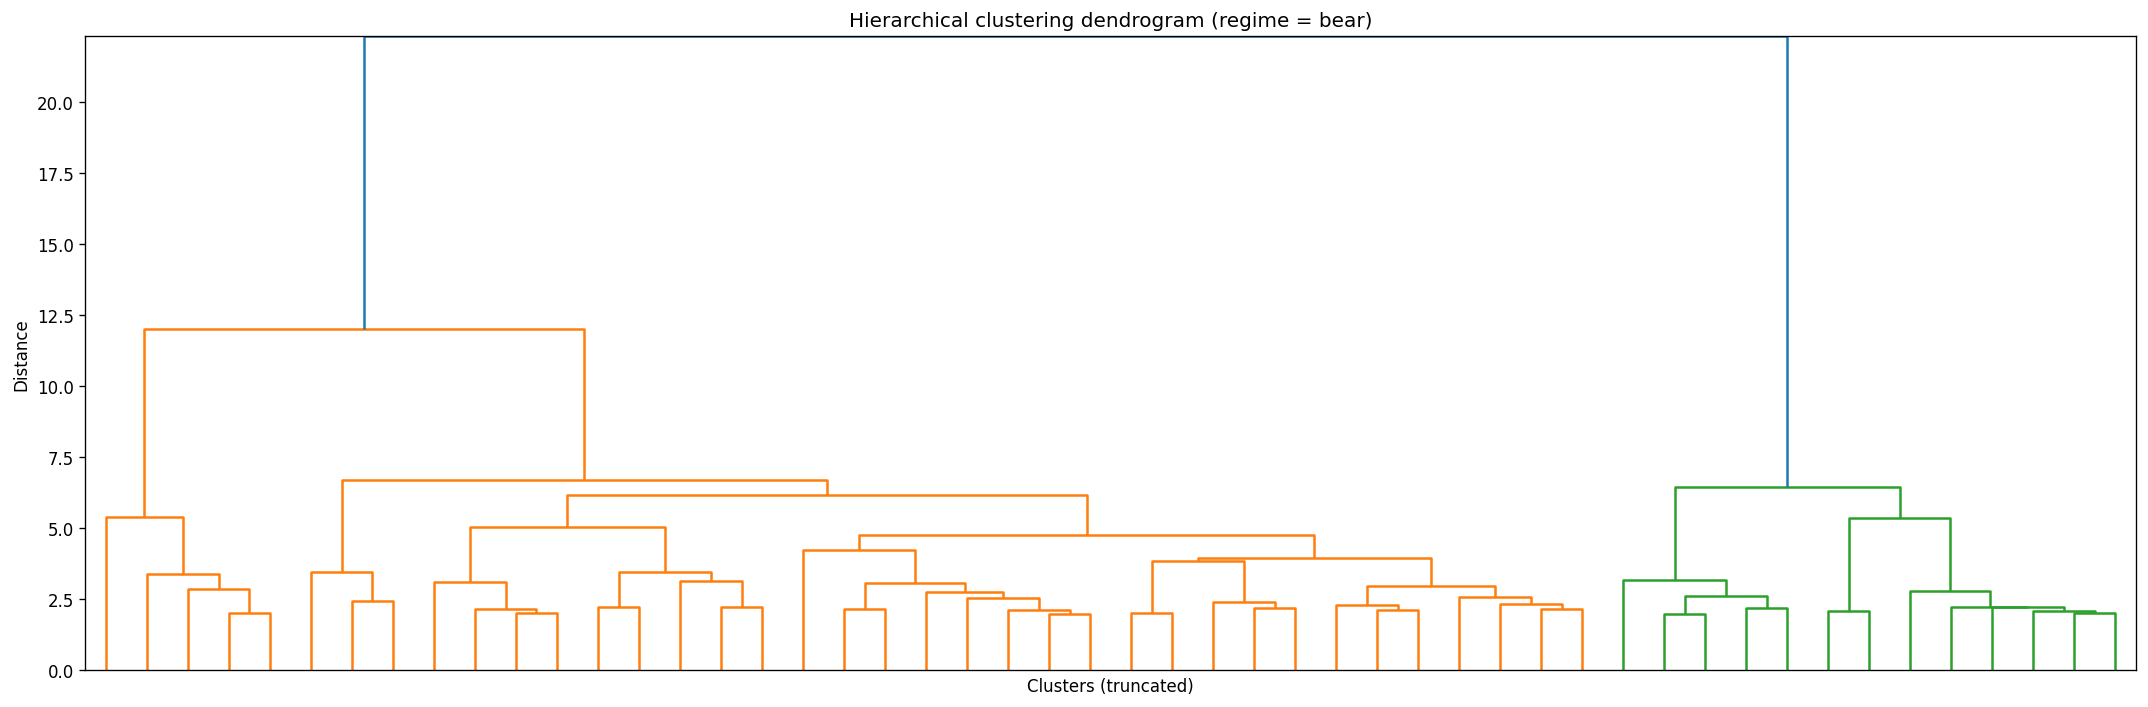

  Saved dendrogram → data_processed/regimes/hierarchical/dendrogram_bear.png
  Saved clusters (k=5) → data_processed/regimes/hierarchical/bear_clusters_k5.csv
  Saved clusters (k=10) → data_processed/regimes/hierarchical/bear_clusters_k10.csv


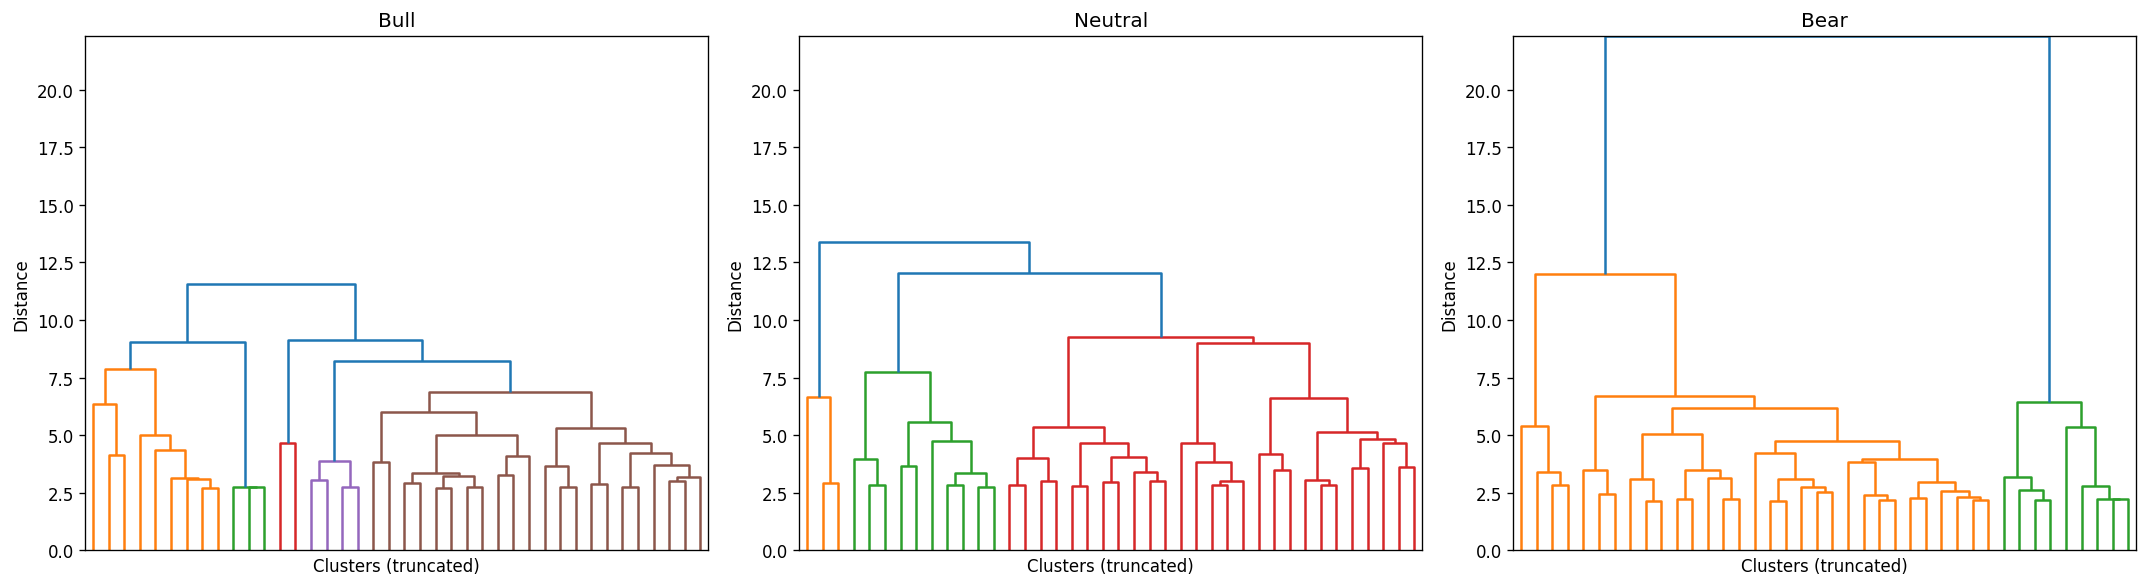

Saved multi-panel comparison → data_processed/regimes/hierarchical/dendrograms_regimes_comparison.png

Step 6 completed with unified dendrogram scale.


In [102]:
# --------------------------------------------------
# 1. Load ETF returns & choose market proxy
# --------------------------------------------------
etf_returns = pd.read_parquet(ETF_RETURNS_FILE)
etf_returns = etf_returns.sort_index()

print("ETF returns shape:", etf_returns.shape)
print("Available ETF symbols:", list(etf_returns.columns))

preferred = ["SPY", "IVV", "VOO"]
market_symbol = None
for sym in preferred:
    if sym in etf_returns.columns:
        market_symbol = sym
        break
if market_symbol is None:
    market_symbol = etf_returns.columns[0]

print("\nUsing market proxy ETF:", market_symbol)
mkt_ret = etf_returns[market_symbol].dropna()   # log-returns


# --------------------------------------------------
# 2. Build indicators: index, drawdown, rolling vol & mean
# --------------------------------------------------
cum_log = mkt_ret.cumsum()
mkt_index = np.exp(cum_log)    # index starting at 1

running_max = mkt_index.cummax()
drawdown = mkt_index / running_max - 1.0

rolling_vol = mkt_ret.rolling(ROLL_WINDOW).std() * np.sqrt(252)
rolling_mean = mkt_ret.rolling(ROLL_WINDOW).mean() * 252

reg = pd.DataFrame({
    "return": mkt_ret,
    "index": mkt_index,
    "drawdown": drawdown,
    "rolling_vol": rolling_vol,
    "rolling_mean": rolling_mean,
})

print("\nIndicator summary:")
display(reg.describe().T)


# --------------------------------------------------
# 3. Define regimes (bull / bear / neutral)
# --------------------------------------------------
vol_lo  = reg["rolling_vol"].quantile(0.25)
vol_hi  = reg["rolling_vol"].quantile(0.75)
dd_deep = reg["drawdown"].quantile(0.10)

print(f"\nVol low  (25% quantile): {vol_lo:.3f}")
print(f"Vol high (75% quantile): {vol_hi:.3f}")
print(f"Deep drawdown threshold: {dd_deep:.3f}")

regime = pd.Series("neutral", index=reg.index)

# Bear: high vol AND deep drawdown
bear_mask = (reg["rolling_vol"] >= vol_hi) & (reg["drawdown"] <= dd_deep)

# Bull: low vol AND positive drift
bull_mask = (reg["rolling_vol"] <= vol_lo) & (reg["rolling_mean"] > 0)

regime[bear_mask] = "bear"
regime[bull_mask] = "bull"

reg["regime"] = regime

print("\nRegime counts:")
print(reg["regime"].value_counts())

reg_out = REGIME_DIR / "market_regimes.csv"
reg.to_csv(reg_out)
print("Saved regime time series →", reg_out)


# --------------------------------------------------
# 4. Regime timeline plot
# --------------------------------------------------
plt.figure(figsize=(12, 5))
ax1 = plt.gca()
ax1.plot(reg.index, reg["index"], label="Market index (from log-returns)")
ax1.set_ylabel("Index level")
ax1.set_title(f"Market regimes based on {market_symbol}")

# colour background by regime
ymin, ymax = reg["index"].min(), reg["index"].max()
for r_name, color in [("bull", "green"), ("bear", "red"), ("neutral", "grey")]:
    mask = reg["regime"] == r_name
    if mask.any():
        ax1.fill_between(
            reg.index,
            ymin,
            ymax,
            where=mask,
            alpha=0.05,
            color=color,
            label=f"{r_name} regime"
        )

handles, labels = ax1.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax1.legend(by_label.values(), by_label.keys(), loc="upper left")

plt.tight_layout()
fig_timeline = REGIME_DIR / "market_regime_timeline.png"
plt.savefig(fig_timeline, dpi=200)
plt.show()
print("Saved regime timeline →", fig_timeline)


# --------------------------------------------------
# 5. Load stock returns & metadata
# --------------------------------------------------
returns = pd.read_parquet(RETURNS_FILE)
returns.index = pd.to_datetime(returns.index)
returns = returns.sort_index()

meta = pd.read_parquet(META_FILE)

print("\nStock returns shape:", returns.shape)
print("Metadata symbols:", meta["symbol"].nunique())

valid_symbols = sorted(set(returns.columns) & set(meta["symbol"].unique()))
returns = returns[valid_symbols]
meta = meta[meta["symbol"].isin(valid_symbols)]

print("After metadata alignment:")
print("  Symbols:", len(valid_symbols))


# --------------------------------------------------
# 6. Helpers: correlation per regime & hierarchical clustering
# --------------------------------------------------
def compute_corr_dist_for_regime(regime_name, min_overlap):
    """Restrict returns to dates in given regime and compute corr & dist."""
    regime_dates = reg.index[reg["regime"] == regime_name]
    if len(regime_dates) == 0:
        print(f"No dates found for regime '{regime_name}'. Skipping.")
        return None, None

    sub = returns.loc[returns.index.isin(regime_dates)]
    print(f"\nRegime '{regime_name}':")
    print(f"  Days in regime:      {len(regime_dates)}")
    print(f"  Rows in sub-returns: {len(sub)}")

    corr = sub.corr(min_periods=min_overlap)
    dist = np.sqrt(2 * (1 - corr))

    corr_file = REGIME_DIR / f"corr_regime_{regime_name}.parquet"
    dist_file = REGIME_DIR / f"dist_regime_{regime_name}.parquet"

    corr.to_parquet(corr_file)
    dist.to_parquet(dist_file)

    print(f"  Saved correlation → {corr_file}")
    print(f"  Saved distance     → {dist_file}")
    return corr, dist


def build_linkage_from_dist(dist):
    """Prepare distance matrix (fill NaNs, diagonal=0) and compute Ward linkage."""
    symbols = dist.index.tolist()
    arr = dist.values.copy()
    median_d = np.nanmedian(arr)
    arr = np.where(np.isnan(arr), median_d, arr)
    np.fill_diagonal(arr, 0.0)

    dist_condensed = squareform(arr)
    Z = linkage(dist_condensed, method="ward")
    return Z, symbols


# --------------------------------------------------
# 7. Compute linkages for all regimes (and record max height)
# --------------------------------------------------
linkages = {}
max_heights = {}

for regime_name in ["bull", "neutral", "bear"]:
    min_overlap = MIN_OVERLAP_PER_REGIME[regime_name]
    corr_r, dist_r = compute_corr_dist_for_regime(regime_name, min_overlap=min_overlap)
    if corr_r is None:
        continue

    finite_frac = np.isfinite(corr_r.values).mean()
    print(f"  Fraction of finite correlations in '{regime_name}': {finite_frac:.3f}")
    if finite_frac < 0.3:
        print(f"  Too many NaNs for regime '{regime_name}', skipping clustering.")
        continue

    Z, symbols = build_linkage_from_dist(dist_r)
    linkages[regime_name] = (Z, symbols)
    max_heights[regime_name] = Z[:, 2].max()

global_max_height = max(max_heights.values())
print("\nGlobal max linkage height across regimes:", global_max_height)


# --------------------------------------------------
# 8. Plot dendrograms per regime with unified y-scale + save clusters
# --------------------------------------------------
for regime_name, (Z, symbols) in linkages.items():
    print(f"\n=== Dendrogram & clusters for regime: {regime_name} ===")

    # Dendrogram with unified y-scale
    plt.figure(figsize=(18, 6))
    dendrogram(
        Z,
        no_labels=True,
        count_sort=True,
        truncate_mode="lastp",
        p=50,
    )
    plt.ylim(0, global_max_height)
    plt.xlabel("Clusters (truncated)")
    plt.ylabel("Distance")
    plt.title(f"Hierarchical clustering dendrogram (regime = {regime_name})")
    plt.tight_layout()
    dendro_file = HIER_DIR / f"dendrogram_{regime_name}.png"
    plt.savefig(dendro_file, dpi=200)
    plt.show()
    print("  Saved dendrogram →", dendro_file)

    # Cluster assignments for different k
    for k in K_LIST:
        labels = fcluster(Z, k, criterion="maxclust")
        df_clusters = pd.DataFrame({
            "symbol": symbols,
            f"cluster_hier_k{k}": labels,
        }).merge(meta, on="symbol", how="left")

        out_csv = HIER_DIR / f"{regime_name}_clusters_k{k}.csv"
        df_clusters.to_csv(out_csv, index=False)
        print(f"  Saved clusters (k={k}) →", out_csv)


# --------------------------------------------------
# 9. Side-by-side comparison figure (bull / neutral / bear)
# --------------------------------------------------
fig, axes = plt.subplots(1, len(linkages), figsize=(6 * len(linkages), 5))

if len(linkages) == 1:
    axes = [axes]

for ax, regime_name in zip(axes, ["bull", "neutral", "bear"]):
    if regime_name not in linkages:
        ax.set_visible(False)
        continue

    Z, _ = linkages[regime_name]
    dendrogram(
        Z,
        no_labels=True,
        count_sort=True,
        truncate_mode="lastp",
        p=40,
        ax=ax,
    )
    ax.set_ylim(0, global_max_height)
    ax.set_title(regime_name.capitalize())
    ax.set_xlabel("Clusters (truncated)")
    ax.set_ylabel("Distance")

plt.tight_layout()
multi_fig = HIER_DIR / "dendrograms_regimes_comparison.png"
plt.savefig(multi_fig, dpi=200)
plt.show()
print("Saved multi-panel comparison →", multi_fig)

print("\nStep 6 completed with unified dendrogram scale.")


# Evaluation

In [104]:
plt.rcParams["figure.dpi"] = 120

# --------------------------------------------------
# 0. Config & paths
# --------------------------------------------------
DATA_DIR = Path("data_processed")

META_FILE = DATA_DIR / "metadata_clean.parquet"

# directories produced in previous steps
HIER_DIR      = DATA_DIR / "clusters_hierarchical"
SPECTRAL_DIR  = DATA_DIR / "clusters_spectral"              # if you used this name
UMAP_DIR      = DATA_DIR / "embedding_umap_hdbscan_kmeans"  # step 5
REGIME_HIER_DIR = DATA_DIR / "regimes" / "hierarchical"     # optional, for later

In [105]:
# --------------------------------------------------
# 1. Load metadata & sector labels
# --------------------------------------------------
meta = pd.read_parquet(META_FILE)

# normalize column names
meta.columns = [c.strip() for c in meta.columns]
if "Symbol" not in meta.columns:
    # try to guess symbol column
    for cand in ["symbol", "ticker", "Ticker"]:
        if cand in meta.columns:
            meta = meta.rename(columns={cand: "Symbol"})
            break

# sector column
if "sector" in meta.columns:
    sector_col = "sector"
elif "Sector" in meta.columns:
    sector_col = "Sector"
else:
    raise ValueError("No 'sector' column found in metadata.")

meta = meta[["Symbol", sector_col]].dropna(subset=[sector_col])
meta.head()

print("Metadata loaded:")
print("  Symbols with sector info:", meta["Symbol"].nunique())


# --------------------------------------------------
# 2. Helper functions
# --------------------------------------------------
def detect_cluster_column(df):
    """Return the first column name that looks like a cluster label."""
    cluster_cols = [c for c in df.columns if "cluster" in c.lower()]
    if not cluster_cols:
        raise ValueError(f"No cluster-like column found in columns: {df.columns}")
    if len(cluster_cols) > 1:
        print("  [warn] Multiple cluster columns found, using first:", cluster_cols)
    return cluster_cols[0]


def load_cluster_file(path, method_name):
    """Load a CSV/parquet cluster file → DataFrame(Symbol, cluster, method)."""
    if path.suffix == ".csv":
        df = pd.read_csv(path)
    else:
        df = pd.read_parquet(path)
    cols_norm = {c: c.strip() for c in df.columns}
    df = df.rename(columns=cols_norm)

    # Symbol column
    if "Symbol" not in df.columns:
        for cand in ["symbol", "ticker", "Ticker"]:
            if cand in df.columns:
                df = df.rename(columns={cand: "Symbol"})
                break
    if "Symbol" not in df.columns:
        raise ValueError(f"No Symbol column in file {path}")

    cluster_col = detect_cluster_column(df)
    df = df[["Symbol", cluster_col]].rename(columns={cluster_col: "cluster"})
    df["method"] = method_name
    return df


def cluster_purity(labels_true, labels_pred):
    """Cluster purity: majority class fraction inside each cluster."""
    df = pd.DataFrame({"true": labels_true, "pred": labels_pred})
    total = len(df)
    purity_sum = 0
    for _, g in df.groupby("pred"):
        purity_sum += g["true"].value_counts().max()
    return purity_sum / total


def sector_to_int(series):
    """Map sector names to integer codes."""
    codes, uniques = pd.factorize(series)
    return codes, dict(enumerate(uniques))


# --------------------------------------------------
# 3. Collect clusterings from different methods
# --------------------------------------------------
clusterings = {}   # method_name -> Series(index=Symbol, data=cluster_id)

# --- 3.1 Hierarchical (baseline)
if HIER_DIR.exists():
    for path in sorted(HIER_DIR.glob("hierarchical_clusters_k*.csv")):
        # file name like hierarchical_clusters_k10.csv
        k_str = path.stem.split("_k")[-1]
        method_name = f"hierarchical_k{k_str}"
        print("Loading", method_name, "from", path)
        df = load_cluster_file(path, method_name)
        clusterings[method_name] = (
            df.set_index("Symbol")["cluster"].astype(int)
        )

# --- 3.2 Spectral clustering
if SPECTRAL_DIR.exists():
    for path in sorted(SPECTRAL_DIR.glob("spectral_clusters_k*.csv")):
        k_str = path.stem.split("_k")[-1]
        method_name = f"spectral_k{k_str}"
        print("Loading", method_name, "from", path)
        df = load_cluster_file(path, method_name)
        clusterings[method_name] = (
            df.set_index("Symbol")["cluster"].astype(int)
        )

# --- 3.3 UMAP + HDBSCAN + K-means
if UMAP_DIR.exists():
    # HDBSCAN (may have -1 for noise)
    hdb_path = UMAP_DIR / "hdbscan_clusters.csv"
    if hdb_path.exists():
        method_name = "hdbscan_umap"
        print("Loading", method_name, "from", hdb_path)
        df = load_cluster_file(hdb_path, method_name)
        s = df.set_index("Symbol")["cluster"].astype(int)
        # Option: drop noise points (-1) for evaluation
        s = s[s != -1]
        clusterings[method_name] = s

    # K-means for different k
    for path in sorted(UMAP_DIR.glob("kmeans_clusters_k*.csv")):
        k_str = path.stem.split("_k")[-1]
        method_name = f"kmeans_umap_k{k_str}"
        print("Loading", method_name, "from", path)
        df = load_cluster_file(path, method_name)
        clusterings[method_name] = (
            df.set_index("Symbol")["cluster"].astype(int)
        )

print("\nCollected methods:", list(clusterings.keys()))

if not clusterings:
    raise RuntimeError("No clustering results found. Check paths.")


# --------------------------------------------------
# 4. Evaluate each method vs. sectors
# --------------------------------------------------
summary_rows = []

for method, s_clusters in clusterings.items():
    # align to metadata with sector info
    df = (
        pd.DataFrame({"Symbol": s_clusters.index, "cluster": s_clusters.values})
        .merge(meta, on="Symbol", how="inner")
        .dropna(subset=[sector_col])
    )

    if df.empty:
        print(f"[warn] No overlap between {method} and metadata; skipping.")
        continue

    # integer-encode sectors
    y_true, sector_map = sector_to_int(df[sector_col])
    y_pred = df["cluster"].astype(int).values

    purity = cluster_purity(y_true, y_pred)
    nmi = normalized_mutual_info_score(y_true, y_pred)
    ari = adjusted_rand_score(y_true, y_pred)

    n_clusters = np.unique(y_pred).size
    n_symbols = df["Symbol"].nunique()

    summary_rows.append({
        "method": method,
        "n_symbols": n_symbols,
        "n_clusters": n_clusters,
        "purity_vs_sector": purity,
        "NMI_vs_sector": nmi,
        "ARI_vs_sector": ari,
    })

summary = pd.DataFrame(summary_rows).sort_values("method").reset_index(drop=True)
print("\n=== Clustering quality vs sectors ===")
display(summary)

summary_out = DATA_DIR / "clustering_evaluation_summary.csv"
summary.to_csv(summary_out, index=False)
print("Saved summary table →", summary_out)


# --------------------------------------------------
# 5. Pairwise method similarity (ARI between methods)
# --------------------------------------------------
pair_rows = []
methods = list(clusterings.keys())

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):
        m1, m2 = methods[i], methods[j]
        s1 = clusterings[m1]
        s2 = clusterings[m2]

        common = s1.index.intersection(s2.index)
        if len(common) < 50:
            # too few overlapping symbols to be meaningful
            continue

        lab1 = s1.loc[common].values
        lab2 = s2.loc[common].values

        ari = adjusted_rand_score(lab1, lab2)
        pair_rows.append({
            "method_1": m1,
            "method_2": m2,
            "n_common_symbols": len(common),
            "ARI_between_methods": ari,
        })

pairwise_ari = pd.DataFrame(pair_rows).sort_values("ARI_between_methods", ascending=False)
print("\n=== Pairwise ARI between clustering methods ===")
display(pairwise_ari.head(20))

pair_out = DATA_DIR / "clustering_pairwise_ari.csv"
pairwise_ari.to_csv(pair_out, index=False)
print("Saved pairwise ARI table →", pair_out)


# --------------------------------------------------
# 6. Example cross-tab for two selected methods (optional)
# --------------------------------------------------
# Choose two methods you care about (edit names as needed)
method_A = "hierarchical_k10"
method_B = "kmeans_umap_k10"

if method_A in clusterings and method_B in clusterings:
    sA = clusterings[method_A]
    sB = clusterings[method_B]
    common = sA.index.intersection(sB.index)

    df_ct = pd.DataFrame({
        method_A: sA.loc[common],
        method_B: sB.loc[common],
    })

    ctab = pd.crosstab(df_ct[method_A], df_ct[method_B])
    print(f"\n=== Cross-tab of clusters: {method_A} vs {method_B} ===")
    display(ctab)

    # Optional: visual heatmap
    plt.figure(figsize=(8, 6))
    plt.imshow(ctab, aspect="auto", cmap="Blues")
    plt.colorbar(label="Count")
    plt.xlabel(method_B + " cluster")
    plt.ylabel(method_A + " cluster")
    plt.title(f"Cluster overlap: {method_A} vs {method_B}")
    plt.tight_layout()
    plt.show()
else:
    print("\n[info] Skipping cross-tab: adjust method_A/method_B names if needed.")

print("\nStep 7 completed.")


Metadata loaded:
  Symbols with sector info: 3702
Loading hierarchical_k10 from data_processed/clusters_hierarchical/hierarchical_clusters_k10.csv
Loading hierarchical_k15 from data_processed/clusters_hierarchical/hierarchical_clusters_k15.csv
Loading hierarchical_k5 from data_processed/clusters_hierarchical/hierarchical_clusters_k5.csv
Loading spectral_k10 from data_processed/clusters_spectral/spectral_clusters_k10.csv
Loading spectral_k15 from data_processed/clusters_spectral/spectral_clusters_k15.csv
Loading spectral_k5 from data_processed/clusters_spectral/spectral_clusters_k5.csv

Collected methods: ['hierarchical_k10', 'hierarchical_k15', 'hierarchical_k5', 'spectral_k10', 'spectral_k15', 'spectral_k5']

=== Clustering quality vs sectors ===


,method,n_symbols,n_clusters,purity_vs_sector,NMI_vs_sector,ARI_vs_sector
0,hierarchical_k10,3045,10,0.373727,0.182954,0.059643
1,hierarchical_k15,3045,15,0.454516,0.254296,0.098247
2,hierarchical_k5,3045,5,0.326765,0.124103,0.035892
3,spectral_k10,3045,10,0.420690,0.246143,0.126807
4,spectral_k15,3045,15,0.439409,0.236914,0.102244
5,spectral_k5,3045,5,0.323810,0.134457,0.043404


Saved summary table → data_processed/clustering_evaluation_summary.csv

=== Pairwise ARI between clustering methods ===


,method_1,method_2,n_common_symbols,ARI_between_methods
0,hierarchical_k10,hierarchical_k15,4623,0.756543
1,hierarchical_k10,hierarchical_k5,4623,0.659958
5,hierarchical_k15,hierarchical_k5,4623,0.461113
11,hierarchical_k5,spectral_k5,4623,0.459597
12,spectral_k10,spectral_k15,4623,0.455197
13,spectral_k10,spectral_k5,4623,0.398101
6,hierarchical_k15,spectral_k10,4623,0.354240
7,hierarchical_k15,spectral_k15,4623,0.341688
3,hierarchical_k10,spectral_k15,4623,0.328048
2,hierarchical_k10,spectral_k10,4623,0.324911


Saved pairwise ARI table → data_processed/clustering_pairwise_ari.csv

[info] Skipping cross-tab: adjust method_A/method_B names if needed.

Step 7 completed.
